<a href="https://colab.research.google.com/github/hsb-ctrl-zy/multi-team1-project/blob/main/%EC%BD%94%EB%9E%A9/%EC%86%8C%EC%83%81%EA%B3%B5%EC%9D%B8vs%EB%8C%80%EA%B8%B0%EC%97%85.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 필요 라이브러리 설치 및 로드

In [71]:
# !pip install pymysql

In [72]:
import pymysql

### SQL 연결

In [73]:
#데이터베이스 연결
conn=pymysql.connect(
    host=host_name,
    user=user_name,
    password=password_val,
    database=db_name,
    port=port_num,
    charset='utf8'
)

### MySQL 연결 상태 확인

In [74]:
if conn:
    try:
        # 커서를 생성하여 쿼리 실행 준비
        with conn.cursor() as cursor:
            # 간단한 쿼리로 현재 연결된 데이터베이스 이름을 확인
            cursor.execute("SELECT DATABASE();")
            result = cursor.fetchone()
            if result and result[0]:
                print(f"데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: {result[0]}")
            else:
                print("데이터베이스에 연결되었지만, 현재 데이터베이스 이름을 가져올 수 없습니다.")
    except pymysql.Error as e:
        print(f"데이터베이스 연결 확인 중 오류 발생: {e}")
        print("연결에 문제가 있을 수 있습니다.")
else:
    print("데이터베이스 연결 객체(conn)가 생성되지 않았습니다. 연결이 실패했을 수 있습니다.")

데이터베이스 연결이 성공적으로 확인되었습니다. 현재 데이터베이스: geo_db


### 형태소 분석을 위한 라이브러리 설치

In [75]:
# !pip install konlpy

In [76]:
# 텍스트 이모티콘 처리를 위한 emoji 라이브러리 설치
# !pip install emoji

### 데이터 로드 및 형태소 분석 준비

In [77]:
import pandas as pd

try:
    with conn.cursor() as cursor:
        # raw_data_table에서 product_name, text_contents, brand_type, page_id, brand_name 컬럼을 가져옵니다.
        sql = "SELECT product_name, text_contents, brand_type, page_id, brand_name FROM raw_data_table"
        cursor.execute(sql)
        data = cursor.fetchall()

    # 데이터를 Pandas DataFrame으로 변환합니다.
    df = pd.DataFrame(data, columns=['product_name', 'text_contents', 'brand_type', 'page_id', 'brand_name'])
    print("데이터를 성공적으로 로드했습니다. 처음 5개 행을 표시합니다:")
    display(df.head())

    print("\nbrand_type 컬럼의 고유 값과 그 개수:")
    display(df['brand_type'].value_counts())

except pymysql.Error as e:
    print(f"데이터 로드 중 오류 발생: {e}")
    df = pd.DataFrame(columns=['product_name', 'text_contents', 'brand_type', 'page_id', 'brand_name'])

데이터를 성공적으로 로드했습니다. 처음 5개 행을 표시합니다:


,product_name,text_contents,brand_type,page_id,brand_name
0,남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759,,대기업,1,CJ
1,트레이닝 반바지 249PT262,[엔비에이][NBA] 스몰로고 트레이닝 반바지(N262TP942P)\n시그니처 로고...,대기업,2,CJ
2,남성 여성 커플 냉장고바지 쿨팬츠 8부 9부 아이스바지,,대기업,3,CJ
3,캘빈클라인 에센셜 셋업 3종 세트 남여공용,,대기업,4,CJ
4,7부 바지 스판 밴딩 냉장고 쿨링 아이스 냉감 칠부 츄리닝 트레이닝 팬츠,,대기업,5,CJ



brand_type 컬럼의 고유 값과 그 개수:


,count
brand_type,
대기업,5750
소상공인,3013


### 'brand_type' 컬럼을 기준으로 데이터 분리

In [78]:
# 'brand_name' 컬럼을 기준으로 데이터 분리 (사전 형태로 저장)
brand_dfs = {}
for brand_name in df['brand_name'].unique():
    brand_dfs[brand_name] = df[df['brand_name'] == brand_name].copy()

print(f"총 {len(brand_dfs)}개의 브랜드 데이터프레임이 생성되었습니다.")

# 예시로 첫 3개 브랜드의 데이터 개수를 출력합니다.
print("\n각 브랜드별 데이터 개수 (상위 3개):")
for i, (brand, brand_df) in enumerate(brand_dfs.items()):
    if i >= 3: # 상위 3개만 출력
        break
    print(f"  - '{brand}' 데이터 개수: {len(brand_df)}개")

총 20개의 브랜드 데이터프레임이 생성되었습니다.

각 브랜드별 데이터 개수 (상위 3개):
  - 'CJ' 데이터 개수: 2794개
  - '홀리' 데이터 개수: 181개
  - '후브스' 데이터 개수: 80개


#### 형태소 분석기 정의

Okt 정의

In [79]:
from konlpy.tag import Okt
import re

okt = Okt()

# --- 특수문자 비율 function (common for all) ---
def get_special_char_ratio(text):
    if not isinstance(text, str) or not text.strip():
        return {'special_char_ratio': 0, 'total_char_count': 0}

    total_char_count = len(text)
    if total_char_count == 0:
        return {'special_char_ratio': 0, 'total_char_count': 0}

    # 한글, 영어, 숫자를 제외한 모든 문자를 특수문자로 간주
    special_char_count = len(re.findall(r'[^\s\w가-힣]', text))

    return {
        'special_char_ratio': special_char_count / total_char_count,
        'total_char_count': total_char_count
    }

# --- Okt Functions ---
def get_pos_ratios(text):
    if not isinstance(text, str) or not text.strip():
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    pos_tags = okt.pos(text)
    total_pos_count = len(pos_tags)

    if total_pos_count == 0:
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    noun_count = sum(1 for word, tag in pos_tags if tag == 'Noun')
    adjective_count = sum(1 for word, tag in pos_tags if tag == 'Adjective')
    numeral_count = sum(1 for word, tag in pos_tags if tag == 'Number')
    verb_count = sum(1 for word, tag in pos_tags if tag == 'Verb')
    josa_count = sum(1 for word, tag in pos_tags if tag == 'Josa')
    eomi_count = sum(1 for word, tag in pos_tags if tag == 'Eomi')

    return {
        'noun_ratio': noun_count / total_pos_count,
        'adjective_ratio': adjective_count / total_pos_count,
        'numeral_ratio': numeral_count / total_pos_count,
        'verb_ratio': verb_count / total_pos_count,
        'josa_ratio': josa_count / total_pos_count,
        'eomi_ratio': eomi_count / total_pos_count,
        'total_pos_count': total_pos_count
    }

print("Okt 형태소 분석기 및 비율 계산 함수 정의 완료.")

Okt 형태소 분석기 및 비율 계산 함수 정의 완료.


KKma 정의

In [80]:
from konlpy.tag import Kkma
import re

kkma = Kkma()

# --- 특수문자 비율 function (common for all) ---
def get_special_char_ratio(text):
    if not isinstance(text, str) or not text.strip():
        return {'special_char_ratio': 0, 'total_char_count': 0}

    total_char_count = len(text)
    if total_char_count == 0:
        return {'special_char_ratio': 0, 'total_char_count': 0}

    # 한글, 영어, 숫자를 제외한 모든 문자를 특수문자로 간주
    special_char_count = len(re.findall(r'[^\s\w가-힣]', text))

    return {
        'special_char_ratio': special_char_count / total_char_count,
        'total_char_count': total_char_count
    }

# --- Kkma Functions ---
def get_pos_ratios_kkma(text):
    if not isinstance(text, str) or not text.strip():
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    pos_tags = kkma.pos(text)
    total_pos_count = len(pos_tags)

    if total_pos_count == 0:
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    noun_count = sum(1 for word, tag in pos_tags if tag.startswith('N'))
    adjective_count = sum(1 for word, tag in pos_tags if tag == 'VA')
    numeral_count = sum(1 for word, tag in pos_tags if tag == 'NR')
    verb_count = sum(1 for word, tag in pos_tags if tag == 'VV')
    josa_count = sum(1 for word, tag in pos_tags if tag.startswith('J'))
    eomi_count = sum(1 for word, tag in pos_tags if tag.startswith('E'))

    return {
        'noun_ratio': noun_count / total_pos_count,
        'adjective_ratio': adjective_count / total_pos_count,
        'numeral_ratio': numeral_count / total_pos_count,
        'verb_ratio': verb_count / total_pos_count,
        'josa_ratio': josa_count / total_pos_count,
        'eomi_ratio': eomi_count / total_pos_count,
        'total_pos_count': total_pos_count
    }

def get_special_char_ratio_kkma(text):
    return get_special_char_ratio(text)

print("Kkma 형태소 분석기 및 비율 계산 함수 정의 완료.")

Kkma 형태소 분석기 및 비율 계산 함수 정의 완료.


Komoran 정의

In [81]:
from konlpy.tag import Komoran
import re

komoran=Komoran()

# --- 특수문자 function (common for all) ---
def get_special_char_ratio(text):
    if not isinstance(text, str) or not text.strip():
        return {'special_char_ratio': 0, 'total_char_count': 0}

    total_char_count = len(text)
    if total_char_count == 0:
        return {'special_char_ratio': 0, 'total_char_count': 0}

    # 한글, 영어, 숫자를 제외한 모든 문자를 특수문자로 간주
    special_char_count = len(re.findall(r'[^\s\w가-힣]', text))

    return {
        'special_char_ratio': special_char_count / total_char_count,
        'total_char_count': total_char_count
    }

# --- Komoran Functions ---
def get_pos_ratios_komoran(text):
    if not isinstance(text, str) or not text.strip():
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    pos_tags = komoran.pos(text)
    total_pos_count = len(pos_tags)

    if total_pos_count == 0:
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    noun_count = sum(1 for word, tag in pos_tags if tag.startswith('N'))
    adjective_count = sum(1 for word, tag in pos_tags if tag == 'VA')
    numeral_count = sum(1 for word, tag in pos_tags if tag == 'NR')
    verb_count = sum(1 for word, tag in pos_tags if tag == 'VV')
    josa_count = sum(1 for word, tag in pos_tags if tag.startswith('J'))
    eomi_count = sum(1 for word, tag in pos_tags if tag.startswith('E'))

    return {
        'noun_ratio': noun_count / total_pos_count,
        'adjective_ratio': adjective_count / total_pos_count,
        'numeral_ratio': numeral_count / total_pos_count,
        'verb_ratio': verb_count / total_pos_count,
        'josa_ratio': josa_count / total_pos_count,
        'eomi_ratio': eomi_count / total_pos_count,
        'total_pos_count': total_pos_count
    }

def get_special_char_ratio_komoran(text):
    return get_special_char_ratio(text)

print("Komoran 형태소 분석기 및 비율 계산 함수 정의 완료.")

Komoran 형태소 분석기 및 비율 계산 함수 정의 완료.


Kiwi 정의

In [ ]:
# !pip install kiwipiepy

In [83]:
from kiwipiepy import Kiwi
import re

kiwi = Kiwi()

# --- 특수문자 function (common for all) ---
def get_special_char_ratio(text):
    if not isinstance(text, str) or not text.strip():
        return {'special_char_ratio': 0, 'total_char_count': 0}

    total_char_count = len(text)
    if total_char_count == 0:
        return {'special_char_ratio': 0, 'total_char_count': 0}

    # 한글, 영어, 숫자를 제외한 모든 문자를 특수문자로 간주
    special_char_count = len(re.findall(r'[^\s\w가-힣]', text))

    return {
        'special_char_ratio': special_char_count / total_char_count,
        'total_char_count': total_char_count
    }

# --- Kiwi Functions ---
def get_pos_ratios_kiwi(text):
    if not isinstance(text, str) or not text.strip():
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    result = kiwi.analyze(text)
    if not result or not result[0]:
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    pos_tags = result[0][0]
    total_pos_count = len(pos_tags)

    if total_pos_count == 0:
        return {'noun_ratio': 0, 'adjective_ratio': 0, 'numeral_ratio': 0, 'verb_ratio': 0, 'josa_ratio': 0, 'eomi_ratio': 0, 'total_pos_count': 0}

    noun_count = sum(1 for word, tag, _, _ in pos_tags if tag.startswith('N'))
    adjective_count = sum(1 for word, tag, _, _ in pos_tags if tag.startswith('VA'))
    numeral_count = sum(1 for word, tag, _, _ in pos_tags if tag.startswith('NR'))
    verb_count = sum(1 for word, tag, _, _ in pos_tags if tag.startswith('V'))
    josa_count = sum(1 for word, tag, _, _ in pos_tags if tag.startswith('J'))
    eomi_count = sum(1 for word, tag, _, _ in pos_tags if tag.startswith('E'))

    return {
        'noun_ratio': noun_count / total_pos_count,
        'adjective_ratio': adjective_count / total_pos_count,
        'numeral_ratio': numeral_count / total_pos_count,
        'verb_ratio': verb_count / total_pos_count,
        'josa_ratio': josa_count / total_pos_count,
        'eomi_ratio': eomi_count / total_pos_count,
        'total_pos_count': total_pos_count
    }

def get_special_char_ratio_kiwi(text):
    return get_special_char_ratio(text)

print("Kiwi 형태소 분석기 및 비율 계산 함수 정의 완료.")

Kiwi 형태소 분석기 및 비율 계산 함수 정의 완료.


#### Okt 형태소 분석 - '대기업' 및 '소상공인' 데이터에 적용

In [84]:
# df_large_enterprise에 Okt 형태소 분석 적용
def apply_okt_analysis_to_df(df_target):
    # product_name 컬럼에 형태소 분석 함수 적용
    product_name_pos_results = df_target['product_name'].apply(get_pos_ratios)
    df_target['product_name_noun_ratio'] = product_name_pos_results.apply(lambda x: x['noun_ratio'])
    df_target['product_name_adjective_ratio'] = product_name_pos_results.apply(lambda x: x['adjective_ratio'])
    df_target['product_name_numeral_ratio'] = product_name_pos_results.apply(lambda x: x['numeral_ratio'])
    df_target['product_name_verb_ratio'] = product_name_pos_results.apply(lambda x: x['verb_ratio'])
    df_target['product_name_josa_ratio'] = product_name_pos_results.apply(lambda x: x['josa_ratio'])
    df_target['product_name_eomi_ratio'] = product_name_pos_results.apply(lambda x: x['eomi_ratio'])

    # product_name 컬럼에 특수문자 비율 함수 적용
    product_name_special_char_results = df_target['product_name'].apply(get_special_char_ratio)
    df_target['product_name_special_char_ratio'] = product_name_special_char_results.apply(lambda x: x['special_char_ratio'])

    # text_contents 컬럼에 형태소 분석 함수 적용
    text_contents_pos_results = df_target['text_contents'].apply(get_pos_ratios)
    df_target['text_contents_noun_ratio'] = text_contents_pos_results.apply(lambda x: x['noun_ratio'])
    df_target['text_contents_adjective_ratio'] = text_contents_pos_results.apply(lambda x: x['adjective_ratio'])
    df_target['text_contents_numeral_ratio'] = text_contents_pos_results.apply(lambda x: x['numeral_ratio'])
    df_target['text_contents_verb_ratio'] = text_contents_pos_results.apply(lambda x: x['verb_ratio'])
    df_target['text_contents_josa_ratio'] = text_contents_pos_results.apply(lambda x: x['josa_ratio'])
    df_target['text_contents_eomi_ratio'] = text_contents_pos_results.apply(lambda x: x['eomi_ratio'])

    # text_contents 컬럼에 특수문자 비율 함수 적용
    text_contents_special_char_results = df_target['text_contents'].apply(get_special_char_ratio)
    df_target['text_contents_special_char_ratio'] = text_contents_special_char_results.apply(lambda x: x['special_char_ratio'])
    return df_target

# brand_dfs를 사용하여 df_large_enterprise와 df_small_business를 재구성
df_large_enterprise_list = []
df_small_business_list = []

for brand_name, brand_df in brand_dfs.items():
    if not brand_df.empty:
        # brand_type 컬럼이 DataFrame 내에 있다고 가정
        if brand_df['brand_type'].iloc[0] == '대기업':
            df_large_enterprise_list.append(brand_df)
        elif brand_df['brand_type'].iloc[0] == '소상공인':
            df_small_business_list.append(brand_df)

df_large_enterprise = pd.concat(df_large_enterprise_list, ignore_index=True) if df_large_enterprise_list else pd.DataFrame()
df_small_business = pd.concat(df_small_business_list, ignore_index=True) if df_small_business_list else pd.DataFrame()

df_large_enterprise = apply_okt_analysis_to_df(df_large_enterprise.copy())
df_small_business = apply_okt_analysis_to_df(df_small_business.copy())

print("Okt 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.")

Okt 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.


#### Kkma 형태소 분석 - '대기업' 및 '소상공인' 데이터에 적용

In [85]:
# df_large_enterprise에 Kkma 형태소 분석 적용
def apply_kkma_analysis_to_df(df_target):
    # product_name 컬럼에 Kkma 형태소 분석 함수 적용
    product_name_pos_results_kkma = df_target['product_name'].apply(get_pos_ratios_kkma)
    df_target['product_name_kkma_noun_ratio'] = product_name_pos_results_kkma.apply(lambda x: x['noun_ratio'])
    df_target['product_name_kkma_adjective_ratio'] = product_name_pos_results_kkma.apply(lambda x: x['adjective_ratio'])
    df_target['product_name_kkma_numeral_ratio'] = product_name_pos_results_kkma.apply(lambda x: x['numeral_ratio'])
    df_target['product_name_kkma_verb_ratio'] = product_name_pos_results_kkma.apply(lambda x: x['verb_ratio'])
    df_target['product_name_kkma_josa_ratio'] = product_name_pos_results_kkma.apply(lambda x: x['josa_ratio'])
    df_target['product_name_kkma_eomi_ratio'] = product_name_pos_results_kkma.apply(lambda x: x['eomi_ratio'])

    # product_name 컬럼에 특수문자 비율 함수 적용 (Kkma 버전)
    product_name_special_char_results_kkma = df_target['product_name'].apply(get_special_char_ratio_kkma)
    df_target['product_name_kkma_special_char_ratio'] = product_name_special_char_results_kkma.apply(lambda x: x['special_char_ratio'])

    # text_contents 컬럼에 Kkma 형태소 분석 함수 적용
    text_contents_pos_results_kkma = df_target['text_contents'].apply(get_pos_ratios_kkma)
    df_target['text_contents_kkma_noun_ratio'] = text_contents_pos_results_kkma.apply(lambda x: x['noun_ratio'])
    df_target['text_contents_kkma_adjective_ratio'] = text_contents_pos_results_kkma.apply(lambda x: x['adjective_ratio'])
    df_target['text_contents_kkma_numeral_ratio'] = text_contents_pos_results_kkma.apply(lambda x: x['numeral_ratio'])
    df_target['text_contents_kkma_verb_ratio'] = text_contents_pos_results_kkma.apply(lambda x: x['verb_ratio'])
    df_target['text_contents_kkma_josa_ratio'] = text_contents_pos_results_kkma.apply(lambda x: x['josa_ratio'])
    df_target['text_contents_kkma_eomi_ratio'] = text_contents_pos_results_kkma.apply(lambda x: x['eomi_ratio'])

    # text_contents 컬럼에 특수문자 비율 함수 적용 (Kkma 버전)
    text_contents_special_char_results_kkma = df_target['text_contents'].apply(get_special_char_ratio_kkma)
    df_target['text_contents_kkma_special_char_ratio'] = text_contents_special_char_results_kkma.apply(lambda x: x['special_char_ratio'])
    return df_target

df_large_enterprise = apply_kkma_analysis_to_df(df_large_enterprise.copy())
df_small_business = apply_kkma_analysis_to_df(df_small_business.copy())

print("Kkma 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.")

Kkma 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.


#### Komoran 형태소 분석 - '대기업' 및 '소상공인' 데이터에 적용

In [86]:
# df_large_enterprise에 Komoran 형태소 분석 적용
def apply_komoran_analysis_to_df(df_target):
    # product_name 컬럼에 Komoran 형태소 분석 함수 적용
    product_name_pos_results_komoran = df_target['product_name'].apply(get_pos_ratios_komoran)
    df_target['product_name_komoran_noun_ratio'] = product_name_pos_results_komoran.apply(lambda x: x['noun_ratio'])
    df_target['product_name_komoran_adjective_ratio'] = product_name_pos_results_komoran.apply(lambda x: x['adjective_ratio'])
    df_target['product_name_komoran_numeral_ratio'] = product_name_pos_results_komoran.apply(lambda x: x['numeral_ratio'])
    df_target['product_name_komoran_verb_ratio'] = product_name_pos_results_komoran.apply(lambda x: x['verb_ratio'])
    df_target['product_name_komoran_josa_ratio'] = product_name_pos_results_komoran.apply(lambda x: x['josa_ratio'])
    df_target['product_name_komoran_eomi_ratio'] = product_name_pos_results_komoran.apply(lambda x: x['eomi_ratio'])

    # product_name 컬럼에 특수문자 비율 함수 적용 (Komoran 버전)
    product_name_special_char_results_komoran = df_target['product_name'].apply(get_special_char_ratio_komoran)
    df_target['product_name_komoran_special_char_ratio'] = product_name_special_char_results_komoran.apply(lambda x: x['special_char_ratio'])

    # text_contents 컬럼에 Komoran 형태소 분석 함수 적용
    text_contents_pos_results_komoran = df_target['text_contents'].apply(get_pos_ratios_komoran)
    df_target['text_contents_komoran_noun_ratio'] = text_contents_pos_results_komoran.apply(lambda x: x['noun_ratio'])
    df_target['text_contents_komoran_adjective_ratio'] = text_contents_pos_results_komoran.apply(lambda x: x['adjective_ratio'])
    df_target['text_contents_komoran_numeral_ratio'] = text_contents_pos_results_komoran.apply(lambda x: x['numeral_ratio'])
    df_target['text_contents_komoran_verb_ratio'] = text_contents_pos_results_komoran.apply(lambda x: x['verb_ratio'])
    df_target['text_contents_komoran_josa_ratio'] = text_contents_pos_results_komoran.apply(lambda x: x['josa_ratio'])
    df_target['text_contents_komoran_eomi_ratio'] = text_contents_pos_results_komoran.apply(lambda x: x['eomi_ratio'])

    # text_contents 컬럼에 특수문자 비율 함수 적용 (Komoran 버전)
    text_contents_special_char_results_komoran = df_target['text_contents'].apply(get_special_char_ratio_komoran)
    df_target['text_contents_komoran_special_char_ratio'] = text_contents_special_char_results_komoran.apply(lambda x: x['special_char_ratio'])
    return df_target

df_large_enterprise = apply_komoran_analysis_to_df(df_large_enterprise.copy())
df_small_business = apply_komoran_analysis_to_df(df_small_business.copy())

print("Komoran 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.")

Komoran 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.


#### Kiwi 형태소 분석 - '대기업' 및 '소상공인' 데이터에 적용

In [87]:
# df_large_enterprise에 Kiwi 형태소 분석 적용
def apply_kiwi_analysis_to_df(df_target):
    # product_name 컬럼에 Kiwi 형태소 분석 함수 적용
    product_name_pos_results_kiwi = df_target['product_name'].apply(get_pos_ratios_kiwi)
    df_target['product_name_kiwi_noun_ratio'] = product_name_pos_results_kiwi.apply(lambda x: x['noun_ratio'])
    df_target['product_name_kiwi_adjective_ratio'] = product_name_pos_results_kiwi.apply(lambda x: x['adjective_ratio'])
    df_target['product_name_kiwi_numeral_ratio'] = product_name_pos_results_kiwi.apply(lambda x: x['numeral_ratio'])
    df_target['product_name_kiwi_verb_ratio'] = product_name_pos_results_kiwi.apply(lambda x: x['verb_ratio'])
    df_target['product_name_kiwi_josa_ratio'] = product_name_pos_results_kiwi.apply(lambda x: x['josa_ratio'])
    df_target['product_name_kiwi_eomi_ratio'] = product_name_pos_results_kiwi.apply(lambda x: x['eomi_ratio'])

    # product_name 컬럼에 특수문자 비율 함수 적용 (Kiwi 버전)
    product_name_special_char_results_kiwi = df_target['product_name'].apply(get_special_char_ratio_kiwi)
    df_target['product_name_kiwi_special_char_ratio'] = product_name_special_char_results_kiwi.apply(lambda x: x['special_char_ratio'])

    # text_contents 컬럼에 Kiwi 형태소 분석 함수 적용
    text_contents_pos_results_kiwi = df_target['text_contents'].apply(get_pos_ratios_kiwi)
    df_target['text_contents_kiwi_noun_ratio'] = text_contents_pos_results_kiwi.apply(lambda x: x['noun_ratio'])
    df_target['text_contents_kiwi_adjective_ratio'] = text_contents_pos_results_kiwi.apply(lambda x: x['adjective_ratio'])
    df_target['text_contents_kiwi_numeral_ratio'] = text_contents_pos_results_kiwi.apply(lambda x: x['numeral_ratio'])
    df_target['text_contents_kiwi_verb_ratio'] = text_contents_pos_results_kiwi.apply(lambda x: x['verb_ratio'])
    df_target['text_contents_kiwi_josa_ratio'] = text_contents_pos_results_kiwi.apply(lambda x: x['josa_ratio'])
    df_target['text_contents_kiwi_eomi_ratio'] = text_contents_pos_results_kiwi.apply(lambda x: x['eomi_ratio'])

    # text_contents 컬럼에 특수문자 비율 함수 적용 (Kiwi 버전)
    text_contents_special_char_results_kiwi = df_target['text_contents'].apply(get_special_char_ratio_kiwi)
    df_target['text_contents_kiwi_special_char_ratio'] = text_contents_special_char_results_kiwi.apply(lambda x: x['special_char_ratio'])
    return df_target

df_large_enterprise = apply_kiwi_analysis_to_df(df_large_enterprise.copy())
df_small_business = apply_kiwi_analysis_to_df(df_small_business.copy())

print("Kiwi 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.")

Kiwi 분석을 이용한 '대기업' 및 '소상공인' 데이터의 형태소 분석 및 특수문자 비율 계산 완료.


#### '대기업' 데이터 분석 결과 (한글 컬럼명)

In [88]:
# '대기업' 데이터의 모든 분석 결과 컬럼들을 통합하여 표시
# Okt, Kkma, Komoran, Kiwi 분석 결과를 포함

# 'product_name' 관련 컬럼
product_name_cols_large = [
    'product_name_noun_ratio', 'product_name_adjective_ratio', 'product_name_numeral_ratio', 'product_name_verb_ratio', 'product_name_josa_ratio', 'product_name_eomi_ratio', 'product_name_special_char_ratio',
    'product_name_kkma_noun_ratio', 'product_name_kkma_adjective_ratio', 'product_name_kkma_numeral_ratio', 'product_name_kkma_verb_ratio', 'product_name_kkma_josa_ratio', 'product_name_kkma_eomi_ratio', 'product_name_kkma_special_char_ratio',
    'product_name_komoran_noun_ratio', 'product_name_komoran_adjective_ratio', 'product_name_komoran_numeral_ratio', 'product_name_komoran_verb_ratio', 'product_name_komoran_josa_ratio', 'product_name_komoran_eomi_ratio', 'product_name_komoran_special_char_ratio',
    'product_name_kiwi_noun_ratio', 'product_name_kiwi_adjective_ratio', 'product_name_kiwi_numeral_ratio', 'product_name_kiwi_verb_ratio', 'product_name_kiwi_josa_ratio', 'product_name_kiwi_eomi_ratio', 'product_name_kiwi_special_char_ratio'
]

# 'text_contents' 관련 컬럼
text_contents_cols_large = [
    'text_contents_noun_ratio', 'text_contents_adjective_ratio', 'text_contents_numeral_ratio', 'text_contents_verb_ratio', 'text_contents_josa_ratio', 'text_contents_eomi_ratio', 'text_contents_special_char_ratio',
    'text_contents_kkma_noun_ratio', 'text_contents_kkma_adjective_ratio', 'text_contents_kkma_numeral_ratio', 'text_contents_kkma_verb_ratio', 'text_contents_kkma_josa_ratio', 'text_contents_kkma_eomi_ratio', 'text_contents_kkma_special_char_ratio',
    'text_contents_komoran_noun_ratio', 'text_contents_komoran_adjective_ratio', 'text_contents_komoran_numeral_ratio', 'text_contents_komoran_verb_ratio', 'text_contents_komoran_josa_ratio', 'text_contents_komoran_eomi_ratio', 'text_contents_komoran_special_char_ratio',
    'text_contents_kiwi_noun_ratio', 'text_contents_kiwi_adjective_ratio', 'text_contents_kiwi_numeral_ratio', 'text_contents_kiwi_verb_ratio', 'text_contents_kiwi_josa_ratio', 'text_contents_kiwi_eomi_ratio', 'text_contents_kiwi_special_char_ratio'
]

# 필요한 컬럼만 선택하여 새로운 DataFrame 생성
df_large_enterprise_display = df_large_enterprise[['product_name', 'text_contents'] + product_name_cols_large + text_contents_cols_large].copy()

# 한글 컬럼명 매핑
column_name_mapping = {
    'product_name': '상품명',
    'text_contents': '본문',

    'product_name_noun_ratio': '상품명_Okt_명사_비율',
    'product_name_adjective_ratio': '상품명_Okt_형용사_비율',
    'product_name_numeral_ratio': '상품명_Okt_수사_비율',
    'product_name_verb_ratio': '상품명_Okt_동사_비율',
    'product_name_josa_ratio': '상품명_Okt_조사_비율',
    'product_name_eomi_ratio': '상품명_Okt_어미_비율',
    'product_name_special_char_ratio': '상품명_Okt_특수문자_비율',

    'product_name_kkma_noun_ratio': '상품명_Kkma_명사_비율',
    'product_name_kkma_adjective_ratio': '상품명_Kkma_형용사_비율',
    'product_name_kkma_numeral_ratio': '상품명_Kkma_수사_비율',
    'product_name_kkma_verb_ratio': '상품명_Kkma_동사_비율',
    'product_name_kkma_josa_ratio': '상품명_Kkma_조사_비율',
    'product_name_kkma_eomi_ratio': '상품명_Kkma_어미_비율',
    'product_name_kkma_special_char_ratio': '상품명_Kkma_특수문자_비율',

    'product_name_komoran_noun_ratio': '상품명_Komoran_명사_비율',
    'product_name_komoran_adjective_ratio': '상품명_Komoran_형용사_비율',
    'product_name_komoran_numeral_ratio': '상품명_Komoran_수사_비율',
    'product_name_komoran_verb_ratio': '상품명_Komoran_동사_비율',
    'product_name_komoran_josa_ratio': '상품명_Komoran_조사_비율',
    'product_name_komoran_eomi_ratio': '상품명_Komoran_어미_비율',
    'product_name_komoran_special_char_ratio': '상품명_Komoran_특수문자_비율',

    'product_name_kiwi_noun_ratio': '상품명_Kiwi_명사_비율',
    'product_name_kiwi_adjective_ratio': '상품명_Kiwi_형용사_비율',
    'product_name_kiwi_numeral_ratio': '상품명_Kiwi_수사_비율',
    'product_name_kiwi_verb_ratio': '상품명_Kiwi_동사_비율',
    'product_name_kiwi_josa_ratio': '상품명_Kiwi_조사_비율',
    'product_name_kiwi_eomi_ratio': '상품명_Kiwi_어미_비율',
    'product_name_kiwi_special_char_ratio': '상품명_Kiwi_특수문자_비율',


    'text_contents_noun_ratio': '본문_Okt_명사_비율',
    'text_contents_adjective_ratio': '본문_Okt_형용사_비율',
    'text_contents_numeral_ratio': '본문_Okt_수사_비율',
    'text_contents_verb_ratio': '본문_Okt_동사_비율',
    'text_contents_josa_ratio': '본문_Okt_조사_비율',
    'text_contents_eomi_ratio': '본문_Okt_어미_비율',
    'text_contents_special_char_ratio': '본문_Okt_특수문자_비율',

    'text_contents_kkma_noun_ratio': '본문_Kkma_명사_비율',
    'text_contents_kkma_adjective_ratio': '본문_Kkma_형용사_비율',
    'text_contents_kkma_numeral_ratio': '본문_Kkma_수사_비율',
    'text_contents_kkma_verb_ratio': '본문_Kkma_동사_비율',
    'text_contents_kkma_josa_ratio': '본문_Kkma_조사_비율',
    'text_contents_kkma_eomi_ratio': '본문_Kkma_어미_비율',
    'text_contents_kkma_special_char_ratio': '본문_Kkma_특수문자_비율',

    'text_contents_komoran_noun_ratio': '본문_Komoran_명사_비율',
    'text_contents_komoran_adjective_ratio': '본문_Komoran_형용사_비율',
    'text_contents_komoran_numeral_ratio': '본문_Komoran_수사_비율',
    'text_contents_komoran_verb_ratio': '본문_Komoran_동사_비율',
    'text_contents_komoran_josa_ratio': '본문_Komoran_조사_비율',
    'text_contents_komoran_eomi_ratio': '본문_Komoran_어미_비율',
    'text_contents_komoran_special_char_ratio': '본문_Komoran_특수문자_비율',

    'text_contents_kiwi_noun_ratio': '본문_Kiwi_명사_비율',
    'text_contents_kiwi_adjective_ratio': '본문_Kiwi_형용사_비율',
    'text_contents_kiwi_numeral_ratio': '본문_Kiwi_수사_비율',
    'text_contents_kiwi_verb_ratio': '본문_Kiwi_동사_비율',
    'text_contents_kiwi_josa_ratio': '본문_Kiwi_조사_비율',
    'text_contents_kiwi_eomi_ratio': '본문_Kiwi_어미_비율',
    'text_contents_kiwi_special_char_ratio': '본문_Kiwi_특수문자_비율'
}

df_large_enterprise_display = df_large_enterprise_display.rename(columns=column_name_mapping)

print("'대기업' 데이터 분석 결과 (상위 3개 행):")
display(df_large_enterprise_display.head(3))

'대기업' 데이터 분석 결과 (상위 3개 행):


,상품명,본문,상품명_Okt_명사_비율,상품명_Okt_형용사_비율,상품명_Okt_수사_비율,상품명_Okt_동사_비율,상품명_Okt_조사_비율,상품명_Okt_어미_비율,상품명_Okt_특수문자_비율,상품명_Kkma_명사_비율,...,본문_Komoran_조사_비율,본문_Komoran_어미_비율,본문_Komoran_특수문자_비율,본문_Kiwi_명사_비율,본문_Kiwi_형용사_비율,본문_Kiwi_수사_비율,본문_Kiwi_동사_비율,본문_Kiwi_조사_비율,본문_Kiwi_어미_비율,본문_Kiwi_특수문자_비율
0,남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759,,0.545455,0.0,0.181818,0.0,0.000000,0.0,0.0,0.666667,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00000
1,트레이닝 반바지 249PT262,[엔비에이][NBA] 스몰로고 트레이닝 반바지(N262TP942P)\n시그니처 로고...,0.400000,0.0,0.400000,0.0,0.000000,0.0,0.0,0.800000,...,0.110187,0.139293,0.03578,0.388889,0.032051,0.0,0.064103,0.119658,0.143162,0.03578
2,남성 여성 커플 냉장고바지 쿨팬츠 8부 9부 아이스바지,,0.750000,0.0,0.166667,0.0,0.083333,0.0,0.0,0.857143,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00000


#### '소상공인' 데이터 분석 결과 (한글 컬럼명)

In [89]:
# '소상공인' 데이터의 모든 분석 결과 컬럼들을 통합하여 표시
# Okt, Kkma, Komoran, Kiwi 분석 결과를 포함

# 필요한 컬럼만 선택하여 새로운 DataFrame 생성
df_small_business_display = df_small_business[['product_name', 'text_contents'] + product_name_cols_large + text_contents_cols_large].copy()

# 한글 컬럼명 매핑 (동일한 매핑 사용)
df_small_business_display = df_small_business_display.rename(columns=column_name_mapping)

print("'소상공인' 데이터 분석 결과 (상위 3개 행):")
display(df_small_business_display.head(3))

'소상공인' 데이터 분석 결과 (상위 3개 행):


,상품명,본문,상품명_Okt_명사_비율,상품명_Okt_형용사_비율,상품명_Okt_수사_비율,상품명_Okt_동사_비율,상품명_Okt_조사_비율,상품명_Okt_어미_비율,상품명_Okt_특수문자_비율,상품명_Kkma_명사_비율,...,본문_Komoran_조사_비율,본문_Komoran_어미_비율,본문_Komoran_특수문자_비율,본문_Kiwi_명사_비율,본문_Kiwi_형용사_비율,본문_Kiwi_수사_비율,본문_Kiwi_동사_비율,본문_Kiwi_조사_비율,본문_Kiwi_어미_비율,본문_Kiwi_특수문자_비율
0,[허리잘록!/여름데이트?] 플래닝 핀턱 스트링 나시 블라우스,플래닝 핀턱 스트링 나시 블라우스\n-체형에 맞춰 조절 가능한 끈 길이\n- 허리 ...,0.666667,0.000000,0.000000,0.000000,0.0,0.0,0.151515,0.571429,...,0.079208,0.118812,0.056522,0.435644,0.019802,0.0,0.079208,0.059406,0.118812,0.056522
1,[팔뚝삭제/허얇핏] 앤드리 도트 콩단추 반팔 블라우스,앤드리 도트 콩단추 반팔 블라우스\n- 러블리한 도트 패턴으로 포인트를 더한 블라우...,0.714286,0.000000,0.000000,0.000000,0.0,0.0,0.103448,0.642857,...,0.079208,0.099010,0.049793,0.463158,0.021053,0.0,0.042105,0.073684,0.094737,0.049793
2,*7col [햇빛막아주는/여리!] 파파야 시스루 썸머 루즈핏 셔츠,파파야 시스루 썸머 루즈핏 셔츠\n- 체형에 구애 없는 루즈핏 실루엣\n- 힙을 덮...,0.466667,0.066667,0.066667,0.066667,0.0,0.0,0.138889,0.380952,...,0.074074,0.101852,0.070866,0.427273,0.036364,0.0,0.081818,0.072727,0.100000,0.070866


#### '대기업'과 '소상공인' 데이터 형태소 분석기별 평균 비율 비교

In [90]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 각 형태소 분석기별 평균 비율 계산 함수
def calculate_average_ratios_by_analyzer(df_target, prefix_base, analyzer_suffix=""):
    columns_to_avg = [
        f'{prefix_base}{analyzer_suffix}_noun_ratio',
        f'{prefix_base}{analyzer_suffix}_adjective_ratio',
        f'{prefix_base}{analyzer_suffix}_numeral_ratio',
        f'{prefix_base}{analyzer_suffix}_verb_ratio',
        f'{prefix_base}{analyzer_suffix}_josa_ratio',
        f'{prefix_base}{analyzer_suffix}_eomi_ratio',
        f'{prefix_base}{analyzer_suffix}_special_char_ratio'
    ]
    avg_ratios = df_target[columns_to_avg].mean().to_dict()
    return {k.replace(f'{prefix_base}{analyzer_suffix}_', ''): v for k, v in avg_ratios.items()}

# '대기업' 데이터 평균 비율 계산
avg_large_okt_product_name = calculate_average_ratios_by_analyzer(df_large_enterprise, 'product_name')
avg_large_okt_text_contents = calculate_average_ratios_by_analyzer(df_large_enterprise, 'text_contents')
avg_large_kkma_product_name = calculate_average_ratios_by_analyzer(df_large_enterprise, 'product_name', '_kkma')
avg_large_kkma_text_contents = calculate_average_ratios_by_analyzer(df_large_enterprise, 'text_contents', '_kkma')
avg_large_komoran_product_name = calculate_average_ratios_by_analyzer(df_large_enterprise, 'product_name', '_komoran')
avg_large_komoran_text_contents = calculate_average_ratios_by_analyzer(df_large_enterprise, 'text_contents', '_komoran')
avg_large_kiwi_product_name = calculate_average_ratios_by_analyzer(df_large_enterprise, 'product_name', '_kiwi')
avg_large_kiwi_text_contents = calculate_average_ratios_by_analyzer(df_large_enterprise, 'text_contents', '_kiwi')

# '소상공인' 데이터 평균 비율 계산
avg_small_okt_product_name = calculate_average_ratios_by_analyzer(df_small_business, 'product_name')
avg_small_okt_text_contents = calculate_average_ratios_by_analyzer(df_small_business, 'text_contents')
avg_small_kkma_product_name = calculate_average_ratios_by_analyzer(df_small_business, 'product_name', '_kkma')
avg_small_kkma_text_contents = calculate_average_ratios_by_analyzer(df_small_business, 'text_contents', '_kkma')
avg_small_komoran_product_name = calculate_average_ratios_by_analyzer(df_small_business, 'product_name', '_komoran')
avg_small_komoran_text_contents = calculate_average_ratios_by_analyzer(df_small_business, 'text_contents', '_komoran')
avg_small_kiwi_product_name = calculate_average_ratios_by_analyzer(df_small_business, 'product_name', '_kiwi')
avg_small_kiwi_text_contents = calculate_average_ratios_by_analyzer(df_small_business, 'text_contents', '_kiwi')

print("'대기업' 및 '소상공인' 데이터의 형태소 분석기별 평균 비율 계산 완료.")

'대기업' 및 '소상공인' 데이터의 형태소 분석기별 평균 비율 계산 완료.


#### '상품명' 품사별 평균 비율 비교 ('대기업' vs '소상공인') 시각화

In [ ]:
# 폰트 규정
from google.colab import files
files.upload()

In [111]:
import os
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# --- 사용자 제공 폰트 설정 ---
font_path = '/content/Pretendard－M.ttf' # Colab 업로드 경로 예시 (파일 업로드 후 이 경로를 확인해주세요)

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    font_prop = fm.FontProperties(fname=font_path)
    font_name = font_prop.get_name()
    plt.rc('font', family=font_name)
    print(f"'{font_name}' 폰트 설정 완료.")
else:
    print(f"경로에 '{font_path}' 폰트 파일을 찾을 수 없습니다. 기본 폰트(Malgun Gothic 또는 대체 폰트)를 사용합니다.")
    # Colab에서 Malgun Gothic이 설치되어 있을 경우를 대비 (fallback to Malgun Gothic or DejaVu Sans)
    try:
        fm.findfont('Malgun Gothic', rebuild_if_missing=True) # 폰트 캐시 재생성 시도
        plt.rc('font', family='Malgun Gothic')
        print("Malgun Gothic 폰트가 설치되어 있어 이를 사용합니다.")
    except Exception:
        plt.rc('font', family='DejaVu Sans') # Fallback to a common font
        print("기본 폰트를 찾을 수 없어 'DejaVu Sans'를 사용합니다.")

# --- 전역 스타일 설정 ---
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지
plt.rcParams['text.color'] = 'white'        # 모든 텍스트 색상을 흰색으로 설정
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'
plt.rcParams['figure.facecolor'] = 'none'   # 그림 배경 투명하게
plt.rcParams['axes.facecolor'] = 'none'     # 축 배경 투명하게
plt.rcParams['savefig.facecolor'] = 'none'  # 저장 시 배경 투명하게

# 사용자 정의 컬러 팔레트 (빨강, 초록, 노랑)
CUSTOM_PALETTE = ['#FF7171', '#71FFE7', '#FAF761']


'Pretendard' 폰트 설정 완료.


/tmp/ipykernel_5777/2209900076.py:52: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=product_name_comparison_df[product_name_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
/tmp/ipykernel_5777/2209900076.py:52: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=product_name_comparison_df[product_name_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
/tmp/ipykernel_5777/2209900076.py:52: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=product_name_comparison_df[product_name_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
/tmp/ipykernel_5777/2209900076.py:52: UserWarning: The palett

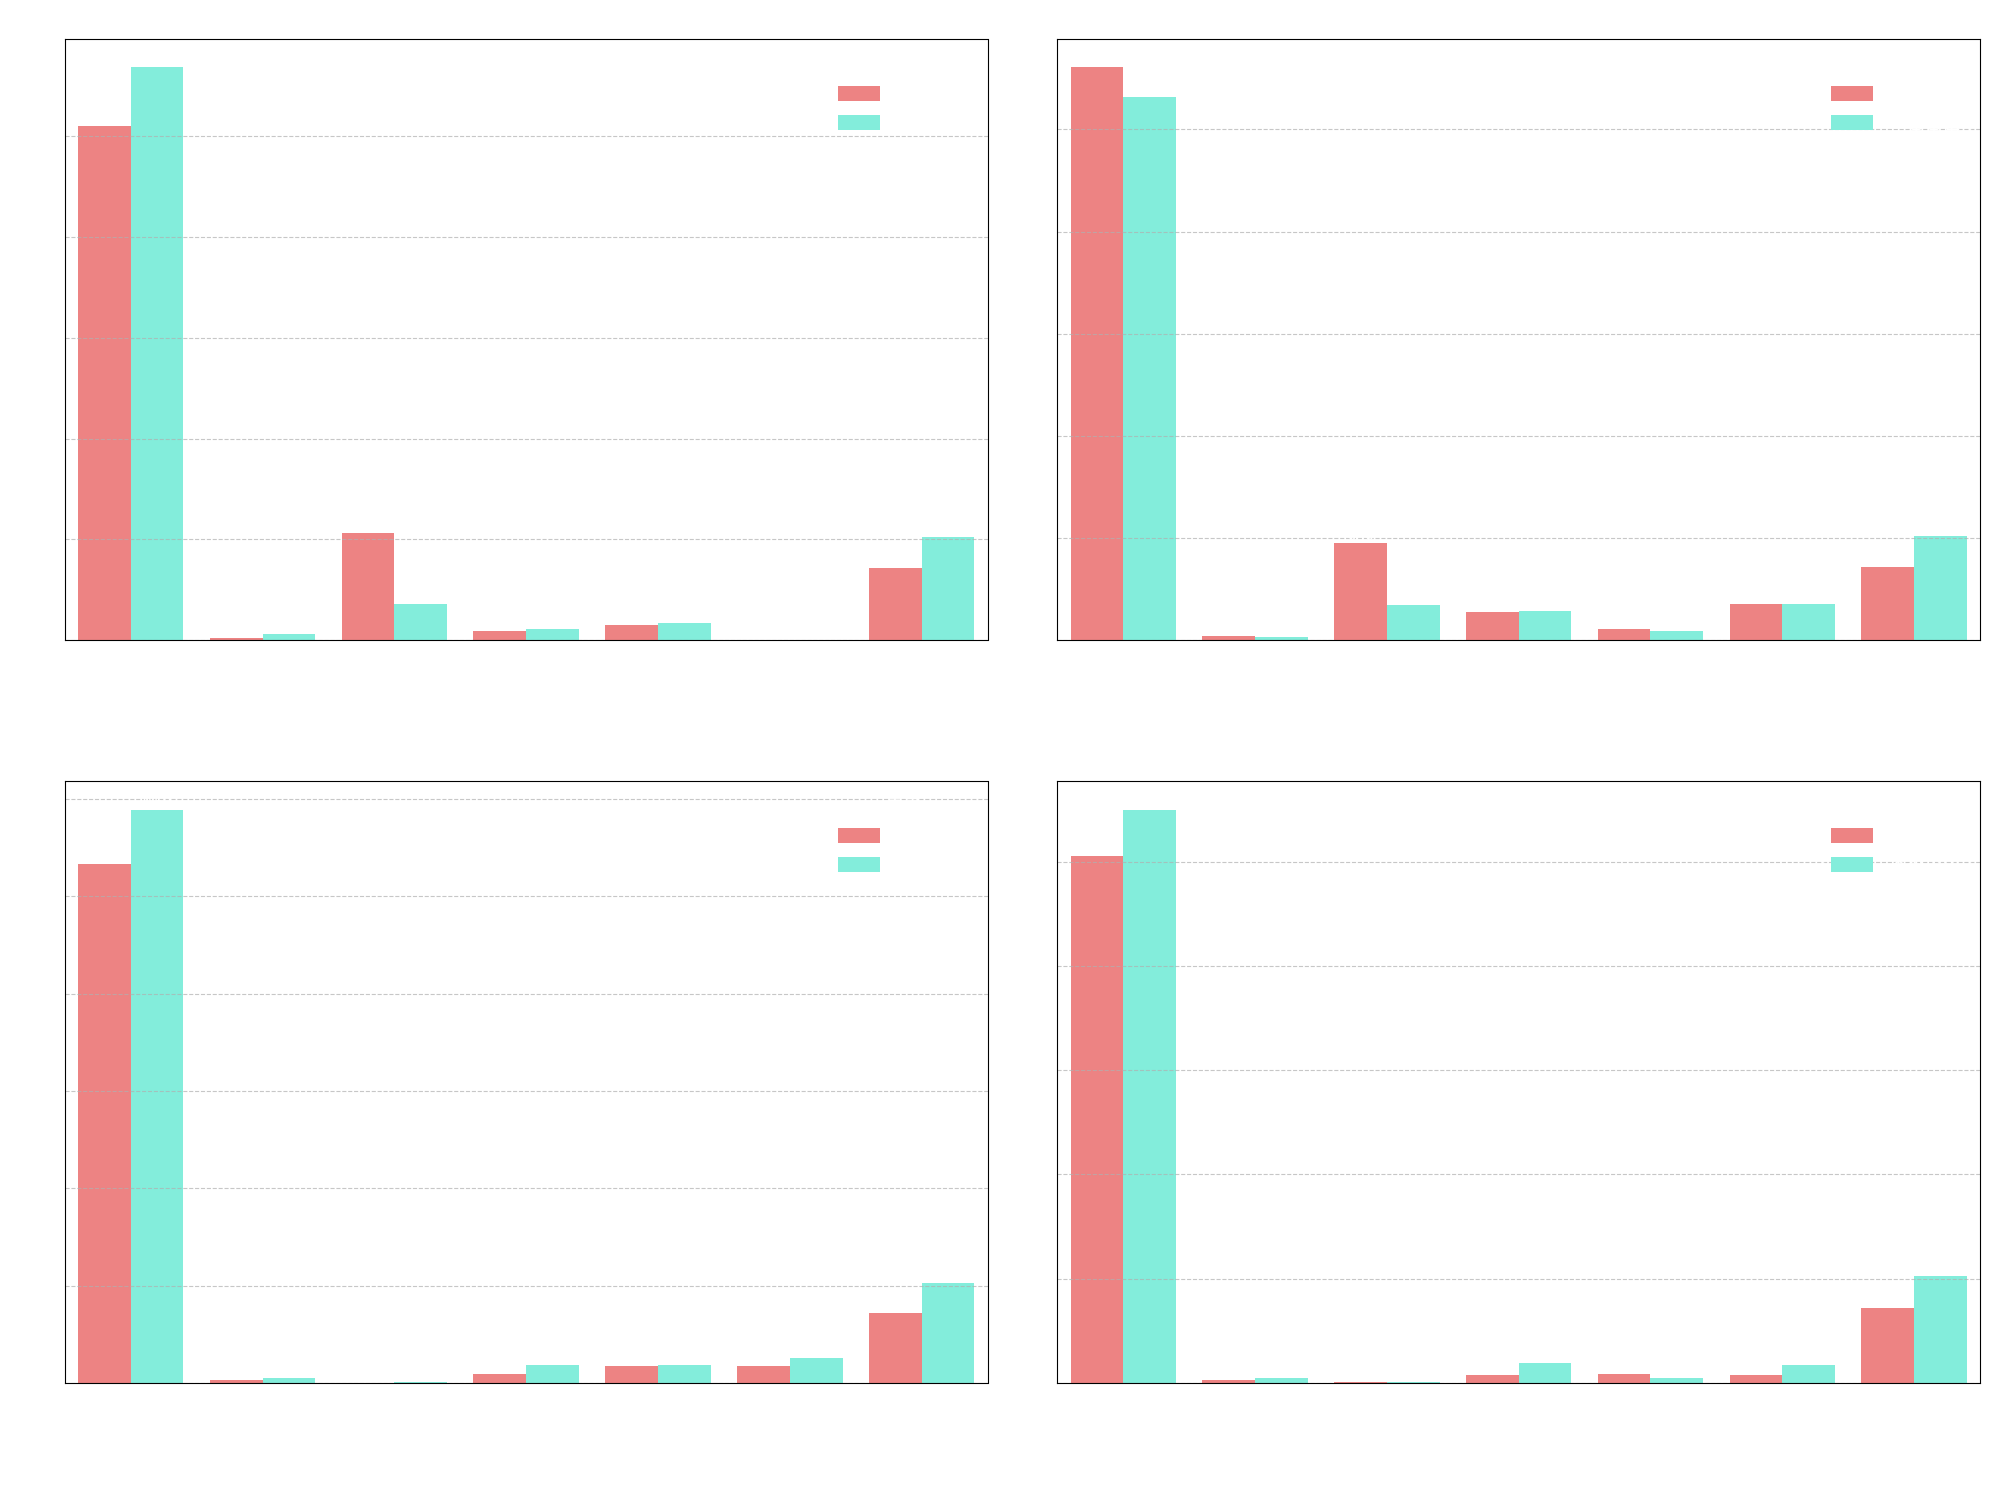

In [120]:
# '상품명' 데이터를 플로팅을 위한 DataFrame으로 변환
product_name_ratios_large_df = pd.DataFrame({
    'Okt': avg_large_okt_product_name,
    'Kkma': avg_large_kkma_product_name,
    'Komoran': avg_large_komoran_product_name,
    'Kiwi': avg_large_kiwi_product_name
}).drop('total_pos_count', errors='ignore')
product_name_ratios_small_df = pd.DataFrame({
    'Okt': avg_small_okt_product_name,
    'Kkma': avg_small_kkma_product_name,
    'Komoran': avg_small_komoran_product_name,
    'Kiwi': avg_small_kiwi_product_name
}).drop('total_pos_count', errors='ignore')

# Dataframe for '대기업'
product_name_ratios_large_melted = product_name_ratios_large_df.T.reset_index().melt(id_vars='index')
product_name_ratios_large_melted.columns = ['Analyzer', 'POS_Type', 'Average_Ratio']
product_name_ratios_large_melted['Group'] = '대기업'

# Dataframe for '소상공인'
product_name_ratios_small_melted = product_name_ratios_small_df.T.reset_index().melt(id_vars='index')
product_name_ratios_small_melted.columns = ['Analyzer', 'POS_Type', 'Average_Ratio']
product_name_ratios_small_melted['Group'] = '소상공인'

# 두 그룹 병합
product_name_comparison_df = pd.concat([product_name_ratios_large_melted, product_name_ratios_small_melted])

# 한글 품사명으로 변경
pos_type_mapping = {
    'noun_ratio': '명사 비율',
    'adjective_ratio': '형용사 비율',
    'numeral_ratio': '수사 비율',
    'verb_ratio': '동사 비율',
    'josa_ratio': '조사 비율',
    'eomi_ratio': '어미 비율',
    'special_char_ratio': '특수문자 비율'
}
product_name_comparison_df['POS_Type'] = product_name_comparison_df['POS_Type'].replace(pos_type_mapping);

# 요청된 순서대로 정렬
ordered_pos_types = ['명사 비율', '형용사 비율', '수사 비율', '동사 비율', '조사 비율', '어미 비율', '특수문자 비율']
product_name_comparison_df['POS_Type'] = pd.Categorical(product_name_comparison_df['POS_Type'], categories=ordered_pos_types, ordered=True)
product_name_comparison_df = product_name_comparison_df.sort_values('POS_Type')

# 각 형태소 분석기별로 그래프 생성 (Subplots 사용)
analyzers = ['Okt', 'Kkma', 'Komoran', 'Kiwi'] # analyzers가 이미 정의되어 있다면 제거해도 됨

fig, axes = plt.subplots(2, 2, figsize=(20, 15))
axes = axes.flatten() # 2x2 grid to 1D array for easy iteration

for i, analyzer in enumerate(analyzers):
    sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=product_name_comparison_df[product_name_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
    axes[i].set_title(f'상품명 품사별 평균 비율 비교: {analyzer} (대기업 vs 소상공인)', fontsize=20, color='white')
    axes[i].set_xlabel('품사 유형', fontsize=15, color='white')
    axes[i].set_ylabel('평균 비율', fontsize=15, color='white')
    axes[i].tick_params(axis='x', rotation=45, colors='white')
    axes[i].tick_params(axis='y', colors='white')
    axes[i].legend(title='그룹', title_fontsize=15, fontsize=15, labelcolor='white', facecolor='none', edgecolor='white')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

    # 각 막대 위에 빈도수 값 표시
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.2f', fontsize=10, color='white')

plt.tight_layout()
plt.savefig('대기업vs소상공인_품사_상품명.png', transparent=True)

plt.show()


#### '본문' 품사별 평균 비율 비교 ('대기업' vs '소상공인') 시각화

/tmp/ipykernel_5777/1927326864.py:44: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=text_contents_comparison_df[text_contents_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
/tmp/ipykernel_5777/1927326864.py:44: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=text_contents_comparison_df[text_contents_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
/tmp/ipykernel_5777/1927326864.py:44: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=text_contents_comparison_df[text_contents_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
/tmp/ipykernel_5777/1927326864.py:44: UserWarning: The 

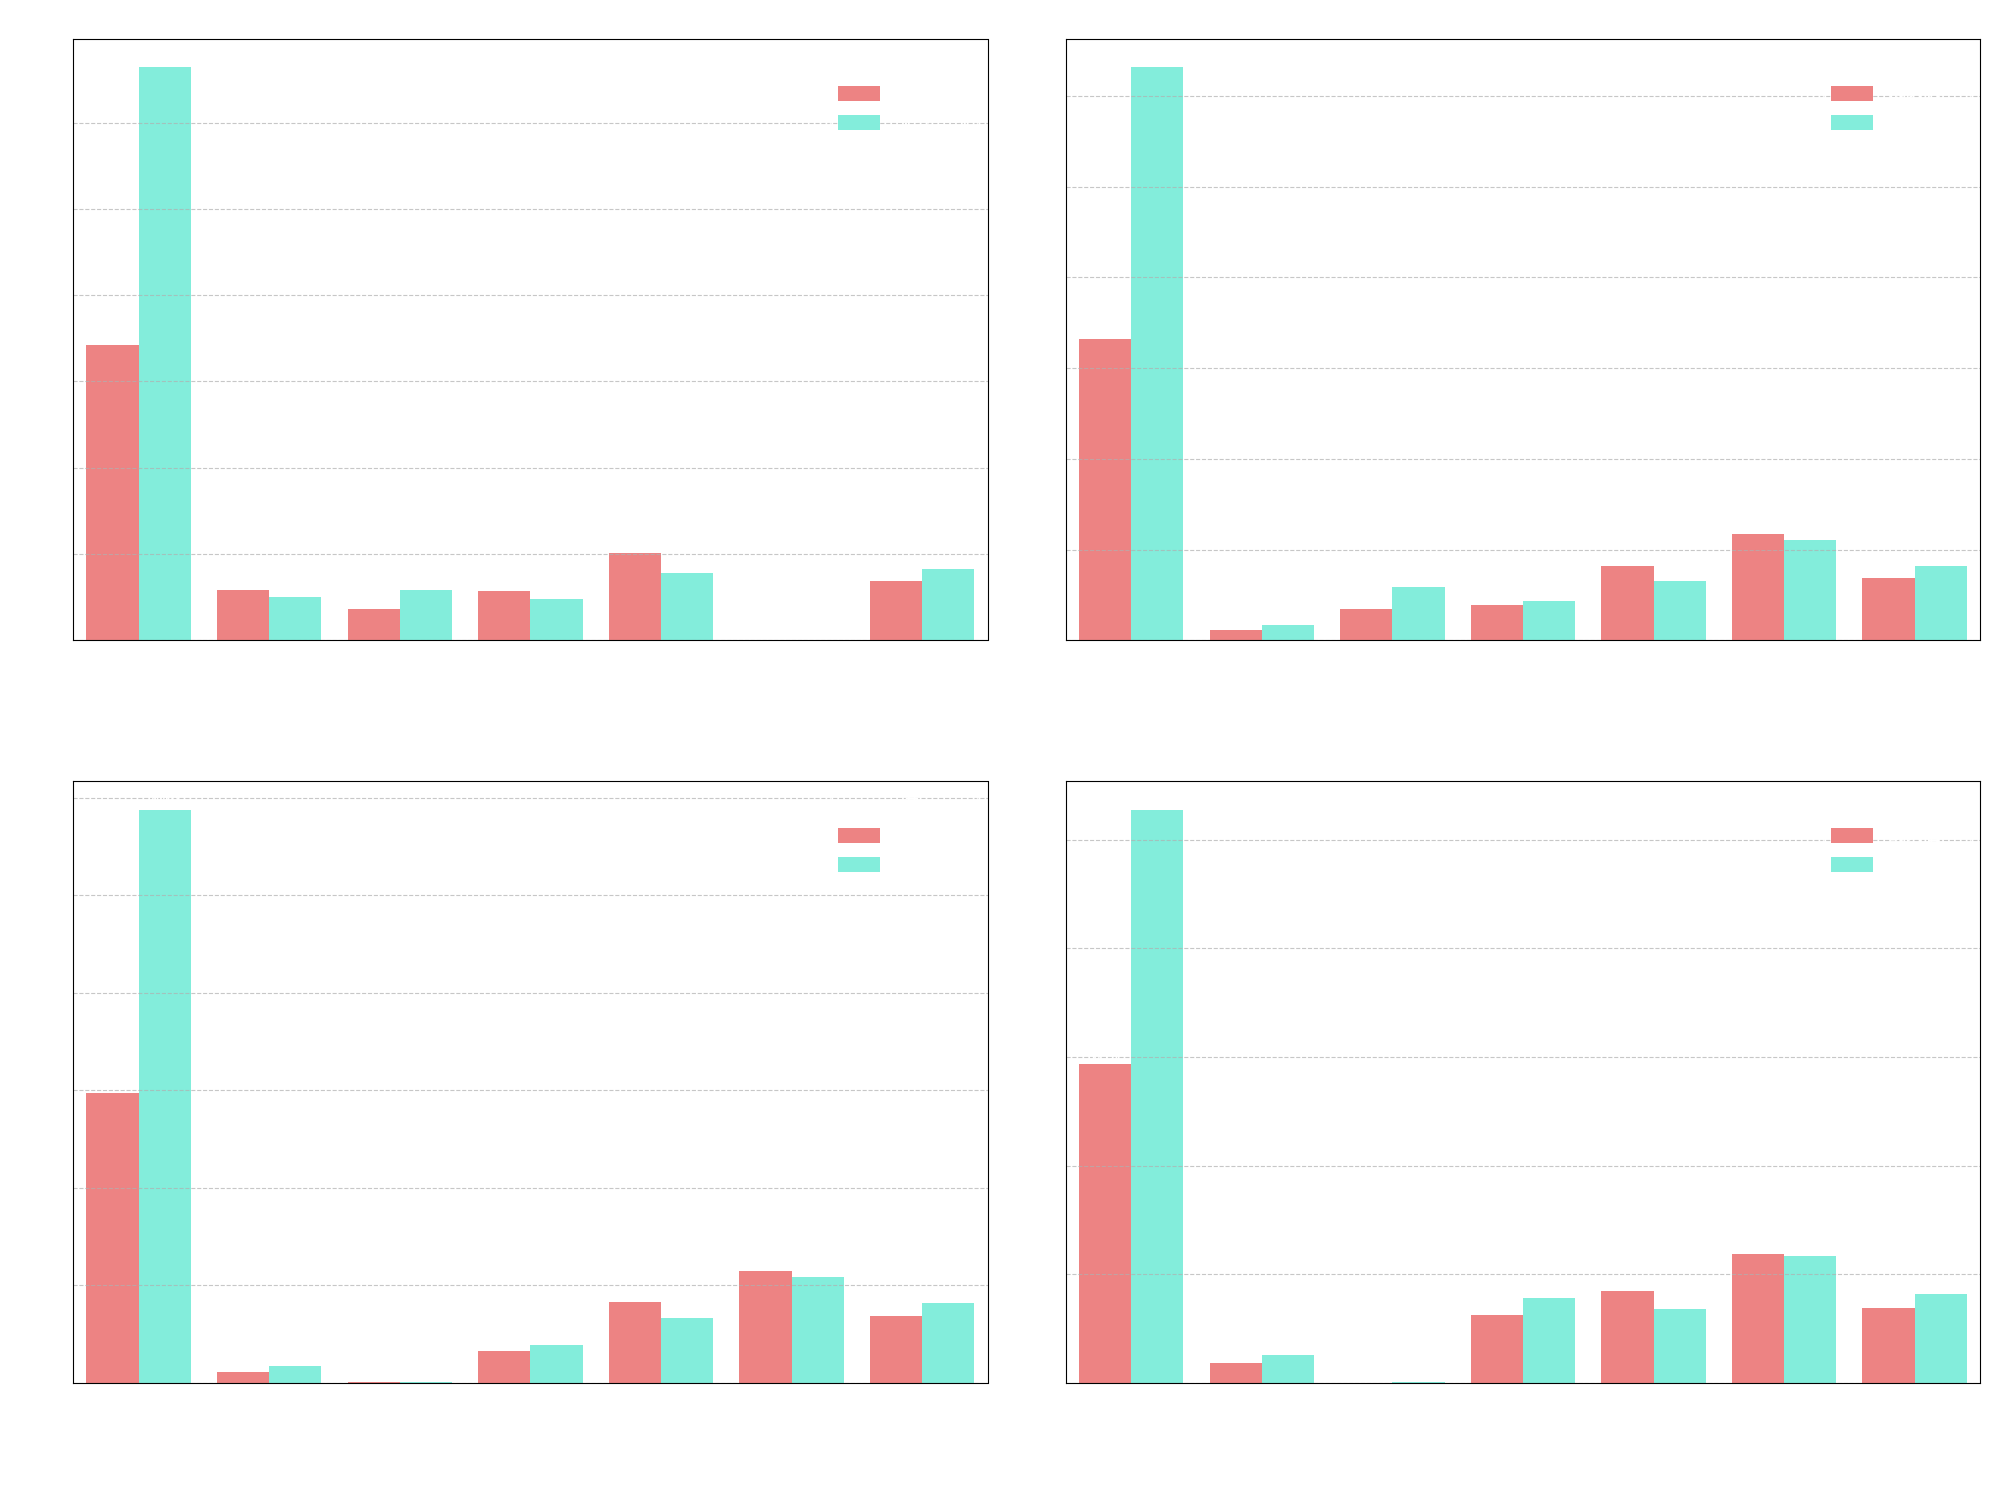

In [121]:
# '본문' 데이터를 플로팅을 위한 DataFrame으로 변환
text_contents_ratios_large_df = pd.DataFrame({
    'Okt': avg_large_okt_text_contents,
    'Kkma': avg_large_kkma_text_contents,
    'Komoran': avg_large_komoran_text_contents,
    'Kiwi': avg_large_kiwi_text_contents
}).drop('total_pos_count', errors='ignore')
text_contents_ratios_small_df = pd.DataFrame({
    'Okt': avg_small_okt_text_contents,
    'Kkma': avg_small_kkma_text_contents,
    'Komoran': avg_small_komoran_text_contents,
    'Kiwi': avg_small_kiwi_text_contents
}).drop('total_pos_count', errors='ignore')

# Dataframe for '대기업'
text_contents_ratios_large_melted = text_contents_ratios_large_df.T.reset_index().melt(id_vars='index')
text_contents_ratios_large_melted.columns = ['Analyzer', 'POS_Type', 'Average_Ratio']
text_contents_ratios_large_melted['Group'] = '대기업'

# Dataframe for '소상공인'
text_contents_ratios_small_melted = text_contents_ratios_small_df.T.reset_index().melt(id_vars='index')
text_contents_ratios_small_melted.columns = ['Analyzer', 'POS_Type', 'Average_Ratio']
text_contents_ratios_small_melted['Group'] = '소상공인'

# 두 그룹 병합
text_contents_comparison_df = pd.concat([text_contents_ratios_large_melted, text_contents_ratios_small_melted])

# 한글 품사명으로 변경
# pos_type_mapping은 이전 셀에서 정의되었으므로 재정의하지 않습니다.
text_contents_comparison_df['POS_Type'] = text_contents_comparison_df['POS_Type'].replace(pos_type_mapping);

# 요청된 순서대로 정렬
# ordered_pos_types는 이전 셀에서 정의되었으므로 재정의하지 않습니다.
text_contents_comparison_df['POS_Type'] = pd.Categorical(text_contents_comparison_df['POS_Type'], categories=ordered_pos_types, ordered=True)
text_contents_comparison_df = text_contents_comparison_df.sort_values('POS_Type')

# 각 형태소 분석기별로 그래프 생성 (Subplots 사용)
# analyzers는 이전 셀에서 정의되었으므로 재정의하지 않습니다.

fig, axes = plt.subplots(2, 2, figsize=(20, 15))
axes = axes.flatten() # 2x2 grid to 1D array for easy iteration

for i, analyzer in enumerate(analyzers):
    sns.barplot(x='POS_Type', y='Average_Ratio', hue='Group', data=text_contents_comparison_df[text_contents_comparison_df['Analyzer'] == analyzer], palette=CUSTOM_PALETTE, ax=axes[i])
    axes[i].set_title(f'본문 품사별 평균 비율 비교: {analyzer} (대기업 vs 소상공인)', fontsize=20, color='white')
    axes[i].set_xlabel('품사 유형', fontsize=15, color='white')
    axes[i].set_ylabel('평균 비율', fontsize=15, color='white')
    axes[i].tick_params(axis='x', rotation=45, colors='white')
    axes[i].tick_params(axis='y', colors='white')
    axes[i].legend(title='그룹', title_fontsize=15,fontsize=15, labelcolor='white', facecolor='none', edgecolor='white')
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

    # 각 막대 위에 빈도수 값 표시
    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.2f', fontsize=10, color='white')

plt.tight_layout()
plt.savefig('대기업vs소상공인_품사_본문.png', transparent=True)

plt.show()


## ---- 추가 ---

### 상품명 품사 및 특수문자 개수 카운팅

In [96]:
import emoji

# Okt 형태소 분석기를 사용하여 품사별 개수를 반환하는 함수
def count_pos_tags_okt(text):
    if not isinstance(text, str) or not text.strip():
        return {'noun_count': 0, 'adjective_count': 0, 'numeral_count': 0, 'verb_count': 0, 'josa_count': 0, 'eomi_count': 0}

    pos_tags = okt.pos(text)

    noun_count = sum(1 for word, tag in pos_tags if tag == 'Noun')
    adjective_count = sum(1 for word, tag in pos_tags if tag == 'Adjective')
    numeral_count = sum(1 for word, tag in pos_tags if tag == 'Number')
    verb_count = sum(1 for word, tag in pos_tags if tag == 'Verb')
    josa_count = sum(1 for word, tag in pos_tags if tag == 'Josa')
    eomi_count = sum(1 for word, tag in pos_tags if tag == 'Eomi')

    return {
        'noun_count': noun_count,
        'adjective_count': adjective_count,
        'numeral_count': numeral_count,
        'verb_count': verb_count,
        'josa_count': josa_count,
        'eomi_count': eomi_count
    }

# 특수문자 개수를 세분화하여 반환하는 함수
def count_detailed_special_chars(text):
    if not isinstance(text, str) or not text.strip():
        return {
            'unicode_emoji_count': 0,
            'textual_emoji_count': 0,
            'separator_count': 0,
            'other_symbol_count': 0
        }

    temp_text = text

    # 1. Count Unicode Emojis
    unicode_emojis = emoji.emoji_list(temp_text)
    unicode_emoji_count = len(unicode_emojis)
    for emo_dict in sorted(unicode_emojis, key=lambda x: x['match_start'], reverse=True):
        temp_text = temp_text[:emo_dict['match_start']] + temp_text[emo_dict['match_end']:]

    # 2. Count Textual Emojis (e.g., :sparkles:)
    textual_emoji_matches = re.findall(r':[가-힣ᄀ-ᇿ㄰-㆏ꥠ-꥿가-힯ힰ-퟿!-~]+:', temp_text) # Allow Korean/English/symbols inside textual emoji
    textual_emoji_count = len(textual_emoji_matches)
    for emo in textual_emoji_matches:
        temp_text = temp_text.replace(emo, '', 1)

    # 3. Count Separators (/, |, [], , .)
    separators_matches = re.findall(r'[/\[\](),.|]', temp_text) # Using pipe for OR, and escaping []()
    separator_count = len(separators_matches)
    temp_text = re.sub(r'[/\[\](),.|]', '', temp_text)

    # 4. Count Other Symbols (all other non-Korean, non-alphanumeric, non-whitespace remaining)
    other_symbols_matches = re.findall(r'[^가-힣ᄀ-ᇿ㄰-㆏ꥠ-꥿가-힯ힰ-퟿ -~]', temp_text)
    other_symbol_count = len(other_symbols_matches)

    return {
        'unicode_emoji_count': unicode_emoji_count,
        'textual_emoji_count': textual_emoji_count,
        'separator_count': separator_count,
        'other_symbol_count': other_symbol_count
    }

print("상품명 개수 카운팅 함수 정의 완료.")

상품명 개수 카운팅 함수 정의 완료.


### '대기업' 및 '소상공인' 데이터에 상품명 품사 및 특수문자 개수 적용

In [97]:
import pandas as pd

# brand_dfs 내의 각 브랜드 데이터프레임에 상품명 품사 및 특수문자 개수 적용
for brand_name, brand_df in brand_dfs.items():
    # Okt 품사 개수 적용
    product_name_counts = brand_df['product_name'].apply(count_pos_tags_okt)
    for key in product_name_counts.iloc[0].keys():
        brand_df[f'product_name_okt_{key}'] = product_name_counts.apply(lambda x: x[key])

    # 상세 특수문자 개수 적용
    detailed_counts = brand_df['product_name'].apply(count_detailed_special_chars)
    brand_df['product_name_unicode_emoji_count'] = detailed_counts.apply(lambda x: x['unicode_emoji_count'])
    brand_df['product_name_textual_emoji_count'] = detailed_counts.apply(lambda x: x['textual_emoji_count'])
    brand_df['product_name_separator_count'] = detailed_counts.apply(lambda x: x['separator_count'])
    brand_df['product_name_other_symbol_count'] = detailed_counts.apply(lambda x: x['other_symbol_count'])

    # 변경된 DataFrame을 brand_dfs에 업데이트
    brand_dfs[brand_name] = brand_df

print("각 브랜드 데이터프레임에 상품명 품사 및 특수문자 개수 계산 완료.")

# 예시로 'CJ' 브랜드의 분석 결과 (상위 3개 행)를 출력합니다.
if 'CJ' in brand_dfs:
    print("\n'CJ' 브랜드 데이터 상품명 분석 결과 (상위 3개 행):")
    display(brand_dfs['CJ'][['product_name', 'product_name_okt_noun_count', 'product_name_unicode_emoji_count', 'product_name_textual_emoji_count', 'product_name_separator_count', 'product_name_other_symbol_count']].head(3))
else:
    print("\n'CJ' 브랜드 데이터가 없습니다.")

각 브랜드 데이터프레임에 상품명 품사 및 특수문자 개수 계산 완료.

'CJ' 브랜드 데이터 상품명 분석 결과 (상위 3개 행):


,product_name,product_name_okt_noun_count,product_name_unicode_emoji_count,product_name_textual_emoji_count,product_name_separator_count,product_name_other_symbol_count
0,남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759,6,0,0,0,0
1,트레이닝 반바지 249PT262,2,0,0,0,0
2,남성 여성 커플 냉장고바지 쿨팬츠 8부 9부 아이스바지,9,0,0,0,0


### 상품명 품사 및 특수문자 개수 평균 비교 시각화

/tmp/ipykernel_5777/1160725427.py:56: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.barplot(x='Category', y='Average_Count', hue='Group', data=df_plot, palette=CUSTOM_PALETTE)


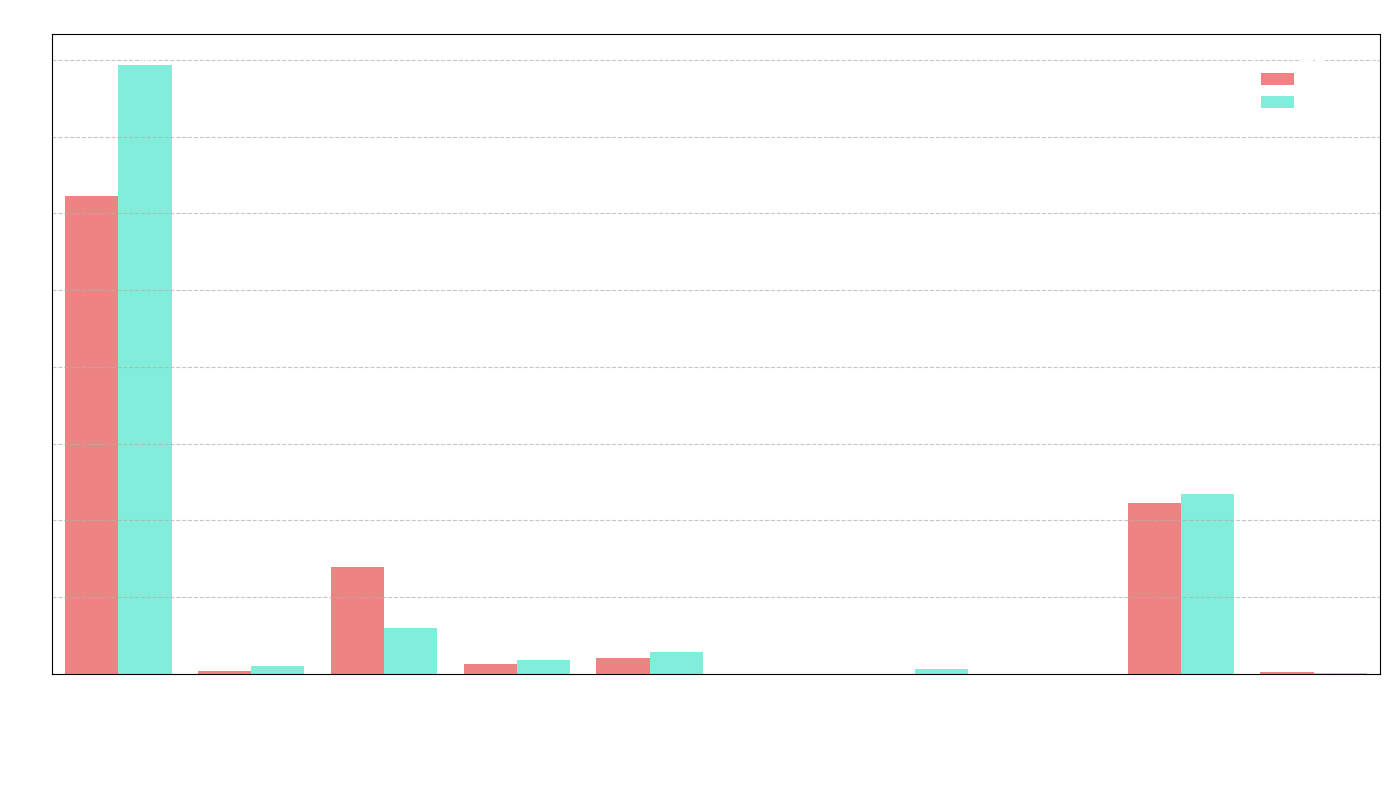

In [114]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# brand_dfs를 사용하여 df_large_enterprise와 df_small_business를 재구성
df_large_enterprise_list = []
df_small_business_list = []

for brand_name, brand_df in brand_dfs.items():
    if not brand_df.empty:
        # brand_type 컬럼이 DataFrame 내에 있다고 가정
        if brand_df['brand_type'].iloc[0] == '대기업':
            df_large_enterprise_list.append(brand_df)
        elif brand_df['brand_type'].iloc[0] == '소상공인':
            df_small_business_list.append(brand_df)

df_large_enterprise = pd.concat(df_large_enterprise_list, ignore_index=True) if df_large_enterprise_list else pd.DataFrame()
df_small_business = pd.concat(df_small_business_list, ignore_index=True) if df_small_business_list else pd.DataFrame()

# 평균 개수 계산
avg_counts_large = {
    '명사': df_large_enterprise['product_name_okt_noun_count'].mean() if not df_large_enterprise.empty else 0,
    '형용사': df_large_enterprise['product_name_okt_adjective_count'].mean() if not df_large_enterprise.empty else 0,
    '수사': df_large_enterprise['product_name_okt_numeral_count'].mean() if not df_large_enterprise.empty else 0,
    '동사': df_large_enterprise['product_name_okt_verb_count'].mean() if not df_large_enterprise.empty else 0,
    '조사': df_large_enterprise['product_name_okt_josa_count'].mean() if not df_large_enterprise.empty else 0,
    '어미': df_large_enterprise['product_name_okt_eomi_count'].mean() if not df_large_enterprise.empty else 0,
    '유니코드 이모지': df_large_enterprise['product_name_unicode_emoji_count'].mean() if not df_large_enterprise.empty else 0,
    '텍스트 이모지': df_large_enterprise['product_name_textual_emoji_count'].mean() if not df_large_enterprise.empty else 0,
    '구분자': df_large_enterprise['product_name_separator_count'].mean() if not df_large_enterprise.empty else 0,
    '기타 특수문자': df_large_enterprise['product_name_other_symbol_count'].mean() if not df_large_enterprise.empty else 0
}

avg_counts_small = {
    '명사': df_small_business['product_name_okt_noun_count'].mean() if not df_small_business.empty else 0,
    '형용사': df_small_business['product_name_okt_adjective_count'].mean() if not df_small_business.empty else 0,
    '수사': df_small_business['product_name_okt_numeral_count'].mean() if not df_small_business.empty else 0,
    '동사': df_small_business['product_name_okt_verb_count'].mean() if not df_small_business.empty else 0,
    '조사': df_small_business['product_name_okt_josa_count'].mean() if not df_small_business.empty else 0,
    '어미': df_small_business['product_name_okt_eomi_count'].mean() if not df_small_business.empty else 0,
    '유니코드 이모지': df_small_business['product_name_unicode_emoji_count'].mean() if not df_small_business.empty else 0,
    '텍스트 이모지': df_small_business['product_name_textual_emoji_count'].mean() if not df_small_business.empty else 0,
    '구분자': df_small_business['product_name_separator_count'].mean() if not df_small_business.empty else 0,
    '기타 특수문자': df_small_business['product_name_other_symbol_count'].mean() if not df_small_business.empty else 0
}

# 데이터를 플로팅을 위한 DataFrame으로 변환
df_plot = pd.DataFrame({
    'Category': list(avg_counts_large.keys()) * 2,
    'Average_Count': list(avg_counts_large.values()) + list(avg_counts_small.values()),
    'Group': ['대기업'] * len(avg_counts_large) + ['소상공인'] * len(avg_counts_small)
})

# 시각화
plt.figure(figsize=(14, 8))
sns.barplot(x='Category', y='Average_Count', hue='Group', data=df_plot, palette=CUSTOM_PALETTE)
plt.title('상품명 품사 및 특수문자 평균 개수 비교 (Okt 분석기)', fontsize=16, color='white')
plt.xlabel('카테고리', fontsize=14, color='white')
plt.ylabel('평균 개수', fontsize=14, color='white')
plt.xticks(rotation=45, ha='right', color='white')
plt.yticks(color='white')
plt.legend(title='그룹', fontsize=12, title_fontsize=12, labelcolor='white', facecolor='none', edgecolor='white')
plt.grid(axis='y', linestyle='--', alpha=0.7)
# 각 막대 위에 빈도수 값 표시
for container in plt.gca().containers:
    plt.bar_label(container, fmt='%.2f', fontsize=10, color='white')

plt.tight_layout()
plt.savefig('대기업vs소상공인_상품명_개수_비교.png', transparent=True)
plt.show()


/tmp/ipykernel_5777/715003070.py:61: UserWarning: 
The palette list has fewer values (3) than needed (20) and will cycle, which may produce an uninterpretable plot.
  ax1 = sns.barplot(
/tmp/ipykernel_5777/715003070.py:98: UserWarning: 
The palette list has fewer values (3) than needed (17) and will cycle, which may produce an uninterpretable plot.
  ax3 = sns.barplot(


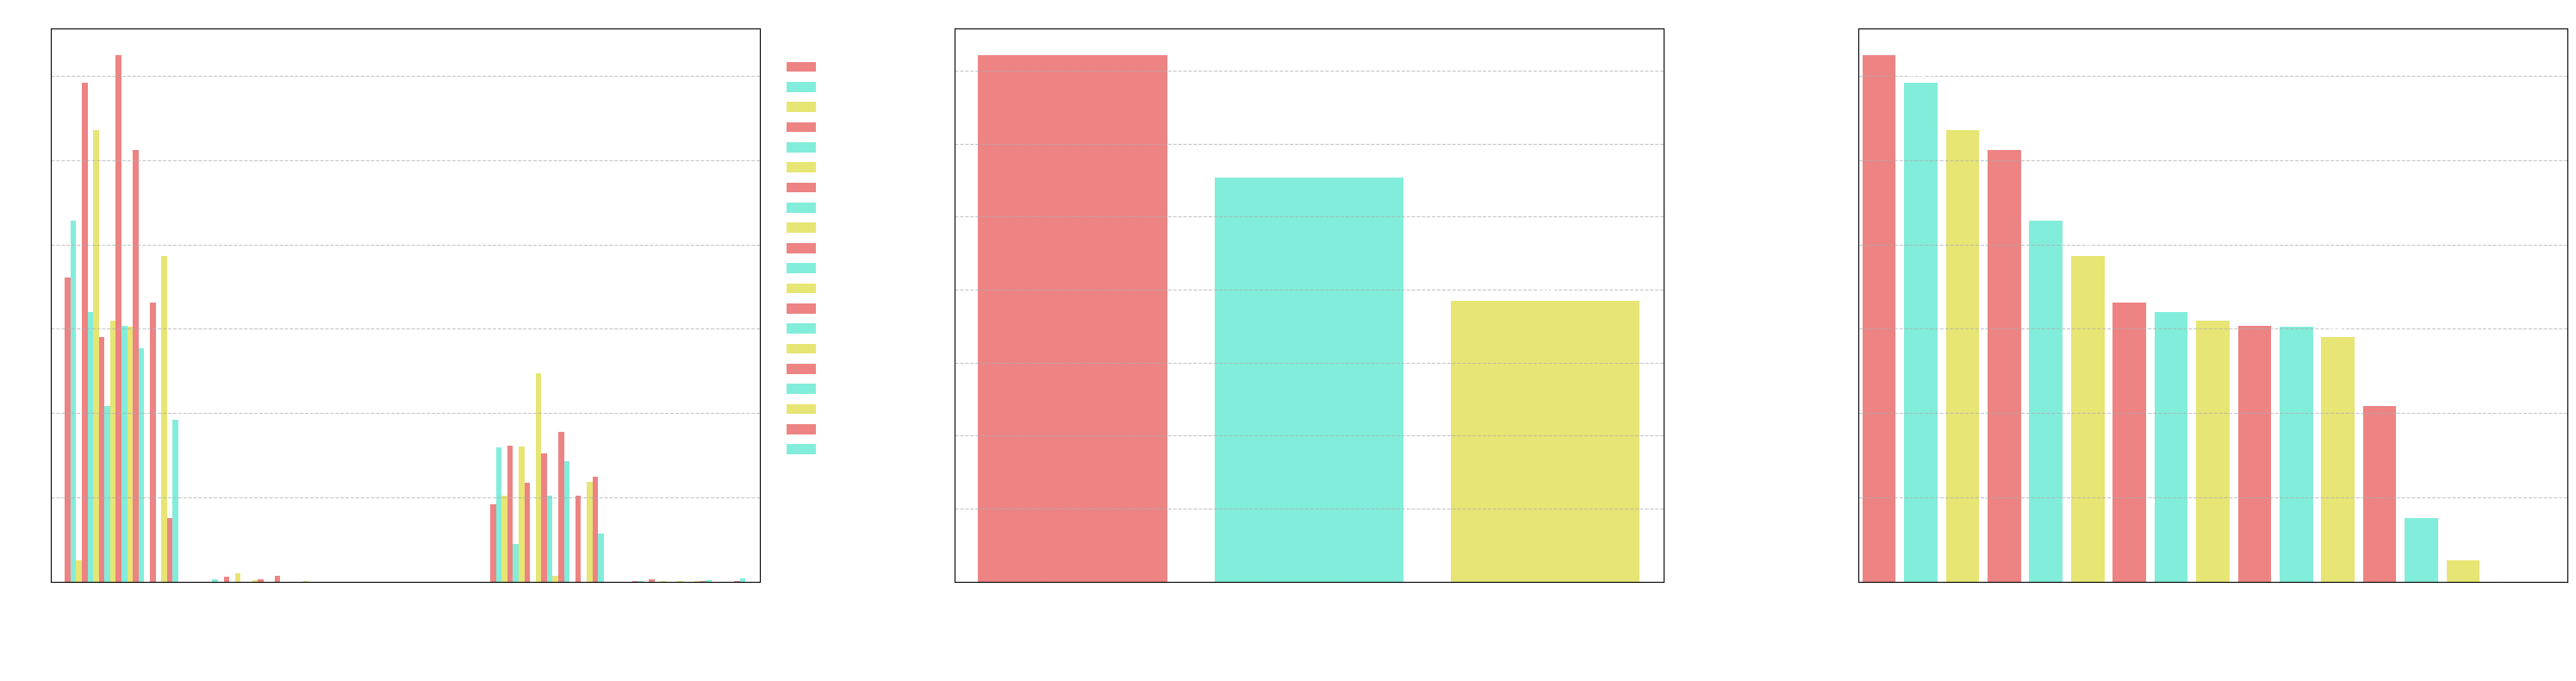

In [119]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 브랜드별 각 항목(품사 및 특수문자) 평균 개수 계산
# brand_dfs 사전의 각 브랜드 데이터프레임을 순회하며 평균값을 추출합니다.
brand_avg_data = []

for brand_name, brand_df in brand_dfs.items():
    if not brand_df.empty:
      # '_cnt' 컬럼이 없으면 '_ratio' 컬럼을 대신 찾도록 처리
      # 이 부분은 현재 count를 직접 사용하므로 필요 없지만, 이전 코드의 흔적으로 남겨둡니다.
        def get_mean(cnt_col, ratio_col):
            if cnt_col in brand_df.columns:
                return brand_df[cnt_col].mean()
            elif ratio_col in brand_df.columns:
                return brand_df[ratio_col].mean()
            return 0
        avg_row = {
            'brand_name': brand_name,
            '명사': brand_df['product_name_okt_noun_count'].mean() if 'product_name_okt_noun_count' in brand_df.columns else 0,
            # '형용사': brand_df['product_name_okt_adjective_count'].mean() if 'product_name_okt_adjective_count' in brand_df.columns else 0,
            # '동사': brand_df['product_name_okt_verb_count'].mean() if 'product_name_okt_verb_count' in brand_df.columns else 0,
            # '수사': brand_df['product_name_okt_numeral_count'].mean() if 'product_name_okt_numeral_count' in brand_df.columns else 0,
            # '조사': brand_df['product_name_okt_josa_count'].mean() if 'product_name_okt_josa_count' in brand_df.columns else 0,
            # '어미': brand_df['product_name_okt_eomi_count'].mean() if 'product_name_okt_eomi_count' in brand_df.columns else 0,
            '유니코드 이모지': brand_df['product_name_unicode_emoji_count'].mean() if 'product_name_unicode_emoji_count' in brand_df.columns else 0,
            '텍스트 이모지': brand_df['product_name_textual_emoji_count'].mean() if 'product_name_textual_emoji_count' in brand_df.columns else 0,
            '구분자': brand_df['product_name_separator_count'].mean() if 'product_name_separator_count' in brand_df.columns else 0,
            '기타 특수문자': brand_df['product_name_other_symbol_count'].mean() if 'product_name_other_symbol_count' in brand_df.columns else 0
        }
        brand_avg_data.append(avg_row)



# DataFrame으로 변환
df_brand_avg = pd.DataFrame(brand_avg_data)

# Assuming df is available from previous cells and contains 'brand_name' and 'brand_type'
# brand_name_to_type 맵핑 생성
brand_name_to_type = df.drop_duplicates(subset=['brand_name'])[['brand_name', 'brand_type']].set_index('brand_name')['brand_type'].to_dict()

# df_brand_avg에 brand_type 컬럼 추가
df_brand_avg['brand_type'] = df_brand_avg['brand_name'].map(brand_name_to_type)

#2. 시각화를 위한 Melt (Long-form 구조로 변환)
df_plot_brand = df_brand_avg.melt(
    id_vars=['brand_name', 'brand_type'], # brand_type을 포함하여 필터링에 사용
    var_name='Category',
    value_name='Average_Count'
)

# 대기업 및 소상공인 명사 평균 개수 데이터프레임 생성
df_large_enterprise_noun_avg = df_brand_avg[df_brand_avg['brand_type'] == '대기업'].sort_values(by='명사', ascending=False)
df_small_business_noun_avg = df_brand_avg[df_brand_avg['brand_type'] == '소상공인'].sort_values(by='명사', ascending=False)

# 2. 서브플롯 생성 (1행 3열 구조로 변경)
fig, axes = plt.subplots(1, 3, figsize=(30, 8)) # 3개의 차트를 위한 figsize 조정

# --- 첫 번째 서브플롯: 카테고리별 브랜드 비교 (기존 ax1, 명사 카테고리 포함) ---
ax1 = sns.barplot(
    data=df_plot_brand, # '명사' 카테고리 다시 포함
    x='Category',
    y='Average_Count',
    hue='brand_name',
    palette=CUSTOM_PALETTE,
    ax=axes[0]
)

axes[0].set_title('브랜드별 상품명 품사 및 특수문자 평균 개수 비교', fontsize=15, fontweight='bold', color='white') # 제목 변경
axes[0].set_xlabel('카테고리', fontsize=15, color='white')
axes[0].set_ylabel('평균 개수', fontsize=15, color='white')
axes[0].tick_params(axis='x', rotation=45, colors='white')
axes[0].tick_params(axis='y', colors='white')
axes[0].legend(title='브랜드명', bbox_to_anchor=(1.02, 1), loc='upper left', title_fontsize=12, fontsize=12, labelcolor='white', facecolor='none', edgecolor='white')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# --- 두 번째 서브플롯: 대기업 브랜드별 상품명 평균 명사 개수 (새로운 ax2) ---
ax2 = sns.barplot(
    data=df_large_enterprise_noun_avg,
    x='brand_name',
    y='명사',
    palette=CUSTOM_PALETTE, # 사용자 정의 팔레트 적용
    hue='brand_name', # hue 인자 추가
    legend=False, # 범례 제거
    ax=axes[1]
)
axes[1].set_title('대기업 브랜드별 상품명 평균 명사 개수 비교', fontsize=15, fontweight='bold', color='white')
axes[1].set_xlabel('브랜드명', fontsize=15, color='white')
axes[1].set_ylabel('평균 명사 개수', fontsize=15, color='white')
axes[1].tick_params(axis='x', rotation=45, colors='white')
axes[1].tick_params(axis='y', colors='white')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f', padding=3, fontsize=9, color='white')

# --- 세 번째 서브플롯: 소상공인 브랜드별 상품명 평균 명사 개수 (새로운 ax3) ---
ax3 = sns.barplot(
    data=df_small_business_noun_avg,
    x='brand_name',
    y='명사',
    palette=CUSTOM_PALETTE, # 사용자 정의 팔레트 적용
    hue='brand_name', # hue 인자 추가
    legend=False, # 범례 제거
    ax=axes[2]
)
axes[2].set_title('소상공인 브랜드별 상품명 평균 명사 개수 비교', fontsize=15, fontweight='bold', color='white')
axes[2].set_xlabel('브랜드명', fontsize=15, color='white')
axes[2].set_ylabel('평균 명사 개수', fontsize=15, color='white')
axes[2].tick_params(axis='x', rotation=45, colors='white')
axes[2].tick_params(axis='y', colors='white')
axes[2].grid(axis='y', linestyle='--', alpha=0.7)
for container in ax3.containers:
    ax3.bar_label(container, fmt='%.2f', padding=3, fontsize=9, color='white')


plt.tight_layout()

plt.savefig('브랜드별_상품명_개수_비교_세분화.png', transparent=True)
plt.show()

### 브랜드별 상품명 명사 빈도 분석 (Top 10)

In [102]:
from collections import Counter

# 상품명에서 명사만 추출하는 함수 (Okt 사용)
def extract_nouns(text):
    if not isinstance(text, str) or not text.strip():
        return []
    nouns = [word for word, tag in okt.pos(text) if tag == 'Noun']
    return nouns

# 각 브랜드별 상품명에서 명사 추출 및 빈도 계산
brand_top_nouns = {}

for brand_name, brand_df in brand_dfs.items():
    all_nouns_brand = []
    for product_name in brand_df['product_name']:
        all_nouns_brand.extend(extract_nouns(product_name))

    noun_counts_brand = Counter(all_nouns_brand)
    top_10_nouns_brand = noun_counts_brand.most_common(10)
    brand_top_nouns[brand_name] = top_10_nouns_brand

    print(f"'{brand_name}' 상품명 명사 빈도 Top 10:")
    for noun, count in top_10_nouns_brand:
        print(f"  - {noun}: {count}회")
    print("\n")

print("모든 브랜드에 대한 상품명 명사 빈도 분석 완료.")

'CJ' 상품명 명사 빈도 Top 10:
  - 남성: 502회
  - 최초: 474회
  - 종: 463회
  - 여름: 393회
  - 세트: 373회
  - 자켓: 360회
  - 팬츠: 314회
  - 여성: 308회
  - 팔: 256회
  - 하프: 239회


'홀리' 상품명 명사 빈도 Top 10:
  - 핏: 51회
  - 티: 39회
  - 루즈: 31회
  - 니트: 29회
  - 나시: 26회
  - 스커트: 25회
  - 미니: 24회
  - 원피스: 21회
  - 오프: 20회
  - 투맨: 20회


'후브스' 상품명 명사 빈도 Top 10:
  - 예약: 20회
  - 배송: 20회


'아이딜릭마켓' 상품명 명사 빈도 Top 10:
  - 팬츠: 201회
  - 빈티: 179회
  - 팔: 179회
  - 스커트: 177회
  - 체크: 164회
  - 니트: 161회
  - 블라우스: 126회
  - 밴딩: 115회
  - 프릴: 107회
  - 드: 101회


'아일랜드모던' 상품명 명사 빈도 Top 10:
  - 후드: 77회
  - 팬츠: 67회
  - 버핏: 61회
  - 티: 54회
  - 티셔츠: 53회
  - 니트: 34회
  - 팔: 33회
  - 와이드: 28회
  - 셔츠: 22회
  - 공용: 21회


'자스민벨' 상품명 명사 빈도 Top 10:
  - 팔: 73회
  - 버핏: 63회
  - 핏: 59회
  - 후드: 47회
  - 티셔츠: 45회
  - 나시: 43회
  - 보장: 37회
  - 자켓: 36회
  - 니트: 35회
  - 가디건: 34회


'르아르' 상품명 명사 빈도 Top 10:
  - 팔: 36회
  - 니트: 26회
  - 셔츠: 20회
  - 블랙: 19회
  - 크롭: 19회
  - 에센셜: 18회
  - 티셔츠: 18회
  - 버뮤다: 17회
  - 쇼츠: 17회
  - 차콜: 15회


'루프온' 상품명 명사 빈도 Top 10:
  - 롱: 39회
  - 티: 32회
  

### 브랜드별 상품명 명사 빈도 시각화 (Top 10)

/tmp/ipykernel_5777/1327995327.py:32: UserWarning: 
The palette list has fewer values (3) than needed (10) and will cycle, which may produce an uninterpretable plot.
  bars = sns.barplot(x=nouns, y=counts, palette=CUSTOM_PALETTE, ax=ax, hue=nouns, legend=False) # hue 인수에 nouns 할당 및 legend=False 추가
/tmp/ipykernel_5777/1327995327.py:32: UserWarning: 
The palette list has fewer values (3) than needed (10) and will cycle, which may produce an uninterpretable plot.
  bars = sns.barplot(x=nouns, y=counts, palette=CUSTOM_PALETTE, ax=ax, hue=nouns, legend=False) # hue 인수에 nouns 할당 및 legend=False 추가
/tmp/ipykernel_5777/1327995327.py:32: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  bars = sns.barplot(x=nouns, y=counts, palette=CUSTOM_PALETTE, ax=ax, hue=nouns, legend=False) # hue 인수에 nouns 할당 및 legend=False 추가
/tmp/ipykernel_5777/1327995327.py:32: UserWarning: 
The palette list has fewer values (3) than needed (10) and will cycle, which may prod

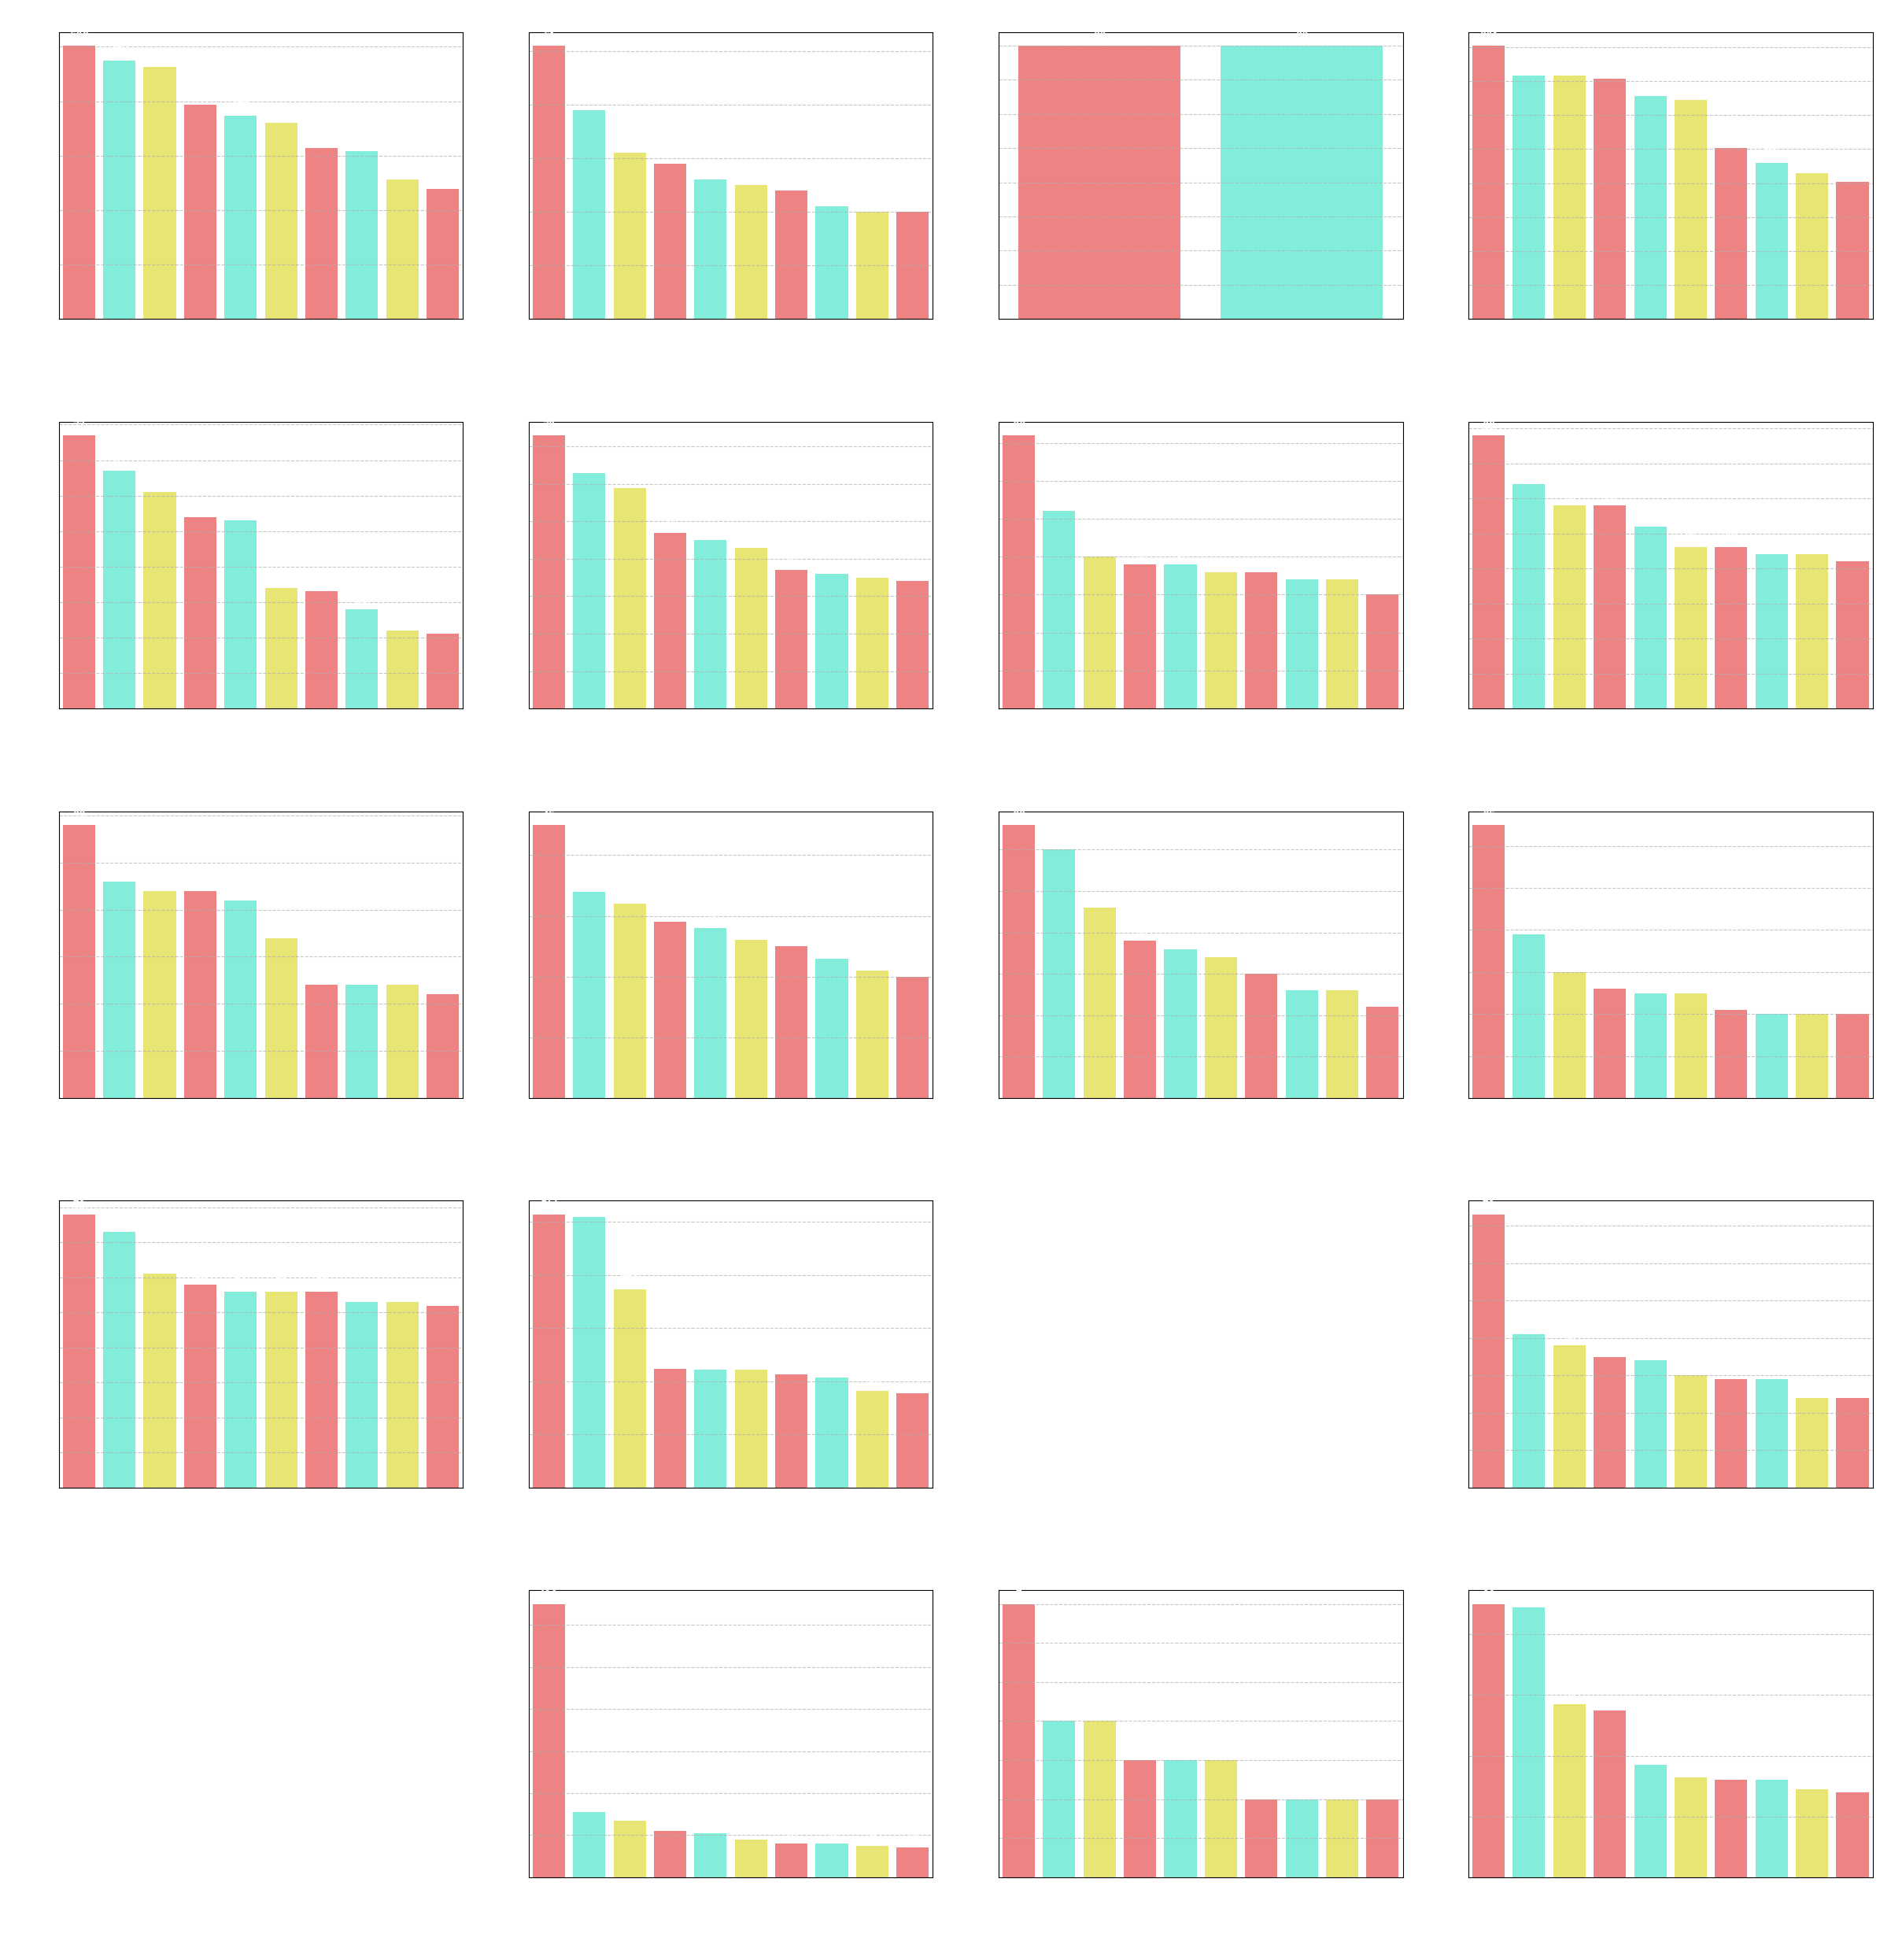

모든 브랜드에 대한 상품명 명사 빈도 통합 시각화 완료.


In [115]:
import matplotlib.pyplot as plt
import seaborn as sns
import math

# 각 브랜드별 상품명 명사 빈도 시각화 (subplots 통합)

# 브랜드 개수 확인
num_brands = len(brand_top_nouns)

# subplot 그리드 크기 계산 (예: 5x4 그리드)
n_cols = 4
n_rows = math.ceil(num_brands / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 6, n_rows * 5)) # 전체 figure 크기 조정
axes = axes.flatten() # 1D 배열로 평탄화하여 반복하기 쉽게 만듬

for i, (brand_name, top_nouns) in enumerate(brand_top_nouns.items()):
    ax = axes[i]

    if not top_nouns: # Top N 명사가 없는 브랜드는 스킵
        ax.set_title(f"'{brand_name}' 분석할 명사 없음",fontsize=20, color='white')
        ax.axis('off') # 그래프를 비활성화
        continue
        #분석할 명사가 없는 경우
          #상품명 자체가 비어 있거나 유효하지 않은 경우
          #명사로 분류될 만한 한국어 단어가 없는 경우
          #상품명이 매우 짧은 경우

    nouns = [noun for noun, count in top_nouns]
    counts = [count for noun, count in top_nouns]

    bars = sns.barplot(x=nouns, y=counts, palette=CUSTOM_PALETTE, ax=ax, hue=nouns, legend=False) # hue 인수에 nouns 할당 및 legend=False 추가
    ax.set_title(f"'{brand_name}' 상품명 명사 빈도 Top 10", fontsize=20, color='white')
    ax.set_xlabel('명사', fontsize=15, color='white')
    ax.set_ylabel('빈도수', fontsize=15, color='white')
    ax.tick_params(axis='x', rotation=45, labelsize=12, colors='white') # 'ha' 인자 제거
    ax.tick_params(axis='y', labelsize=12, colors='white')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # 각 막대 위에 빈도수 값 표시
    for bar in bars.patches:
        ax.annotate(f'{int(bar.get_height())}',
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, color='white')

# 남은 빈 subplot이 있다면 비활성화
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig('모든_브랜드_상품명_명사_빈도_Top10_통합.png', transparent=True)
plt.show()

print("모든 브랜드에 대한 상품명 명사 빈도 통합 시각화 완료.")


/tmp/ipykernel_5777/3172483718.py:59: UserWarning: 
The palette list has fewer values (3) than needed (5) and will cycle, which may produce an uninterpretable plot.
  bars = sns.barplot(x='Category', y='Average_Count', data=brand_data, palette=CUSTOM_PALETTE, ax=ax, hue='Category', legend=False)
/tmp/ipykernel_5777/3172483718.py:59: UserWarning: 
The palette list has fewer values (3) than needed (5) and will cycle, which may produce an uninterpretable plot.
  bars = sns.barplot(x='Category', y='Average_Count', data=brand_data, palette=CUSTOM_PALETTE, ax=ax, hue='Category', legend=False)
/tmp/ipykernel_5777/3172483718.py:59: UserWarning: 
The palette list has fewer values (3) than needed (5) and will cycle, which may produce an uninterpretable plot.
  bars = sns.barplot(x='Category', y='Average_Count', data=brand_data, palette=CUSTOM_PALETTE, ax=ax, hue='Category', legend=False)
/tmp/ipykernel_5777/3172483718.py:59: UserWarning: 
The palette list has fewer values (3) than needed (5) and

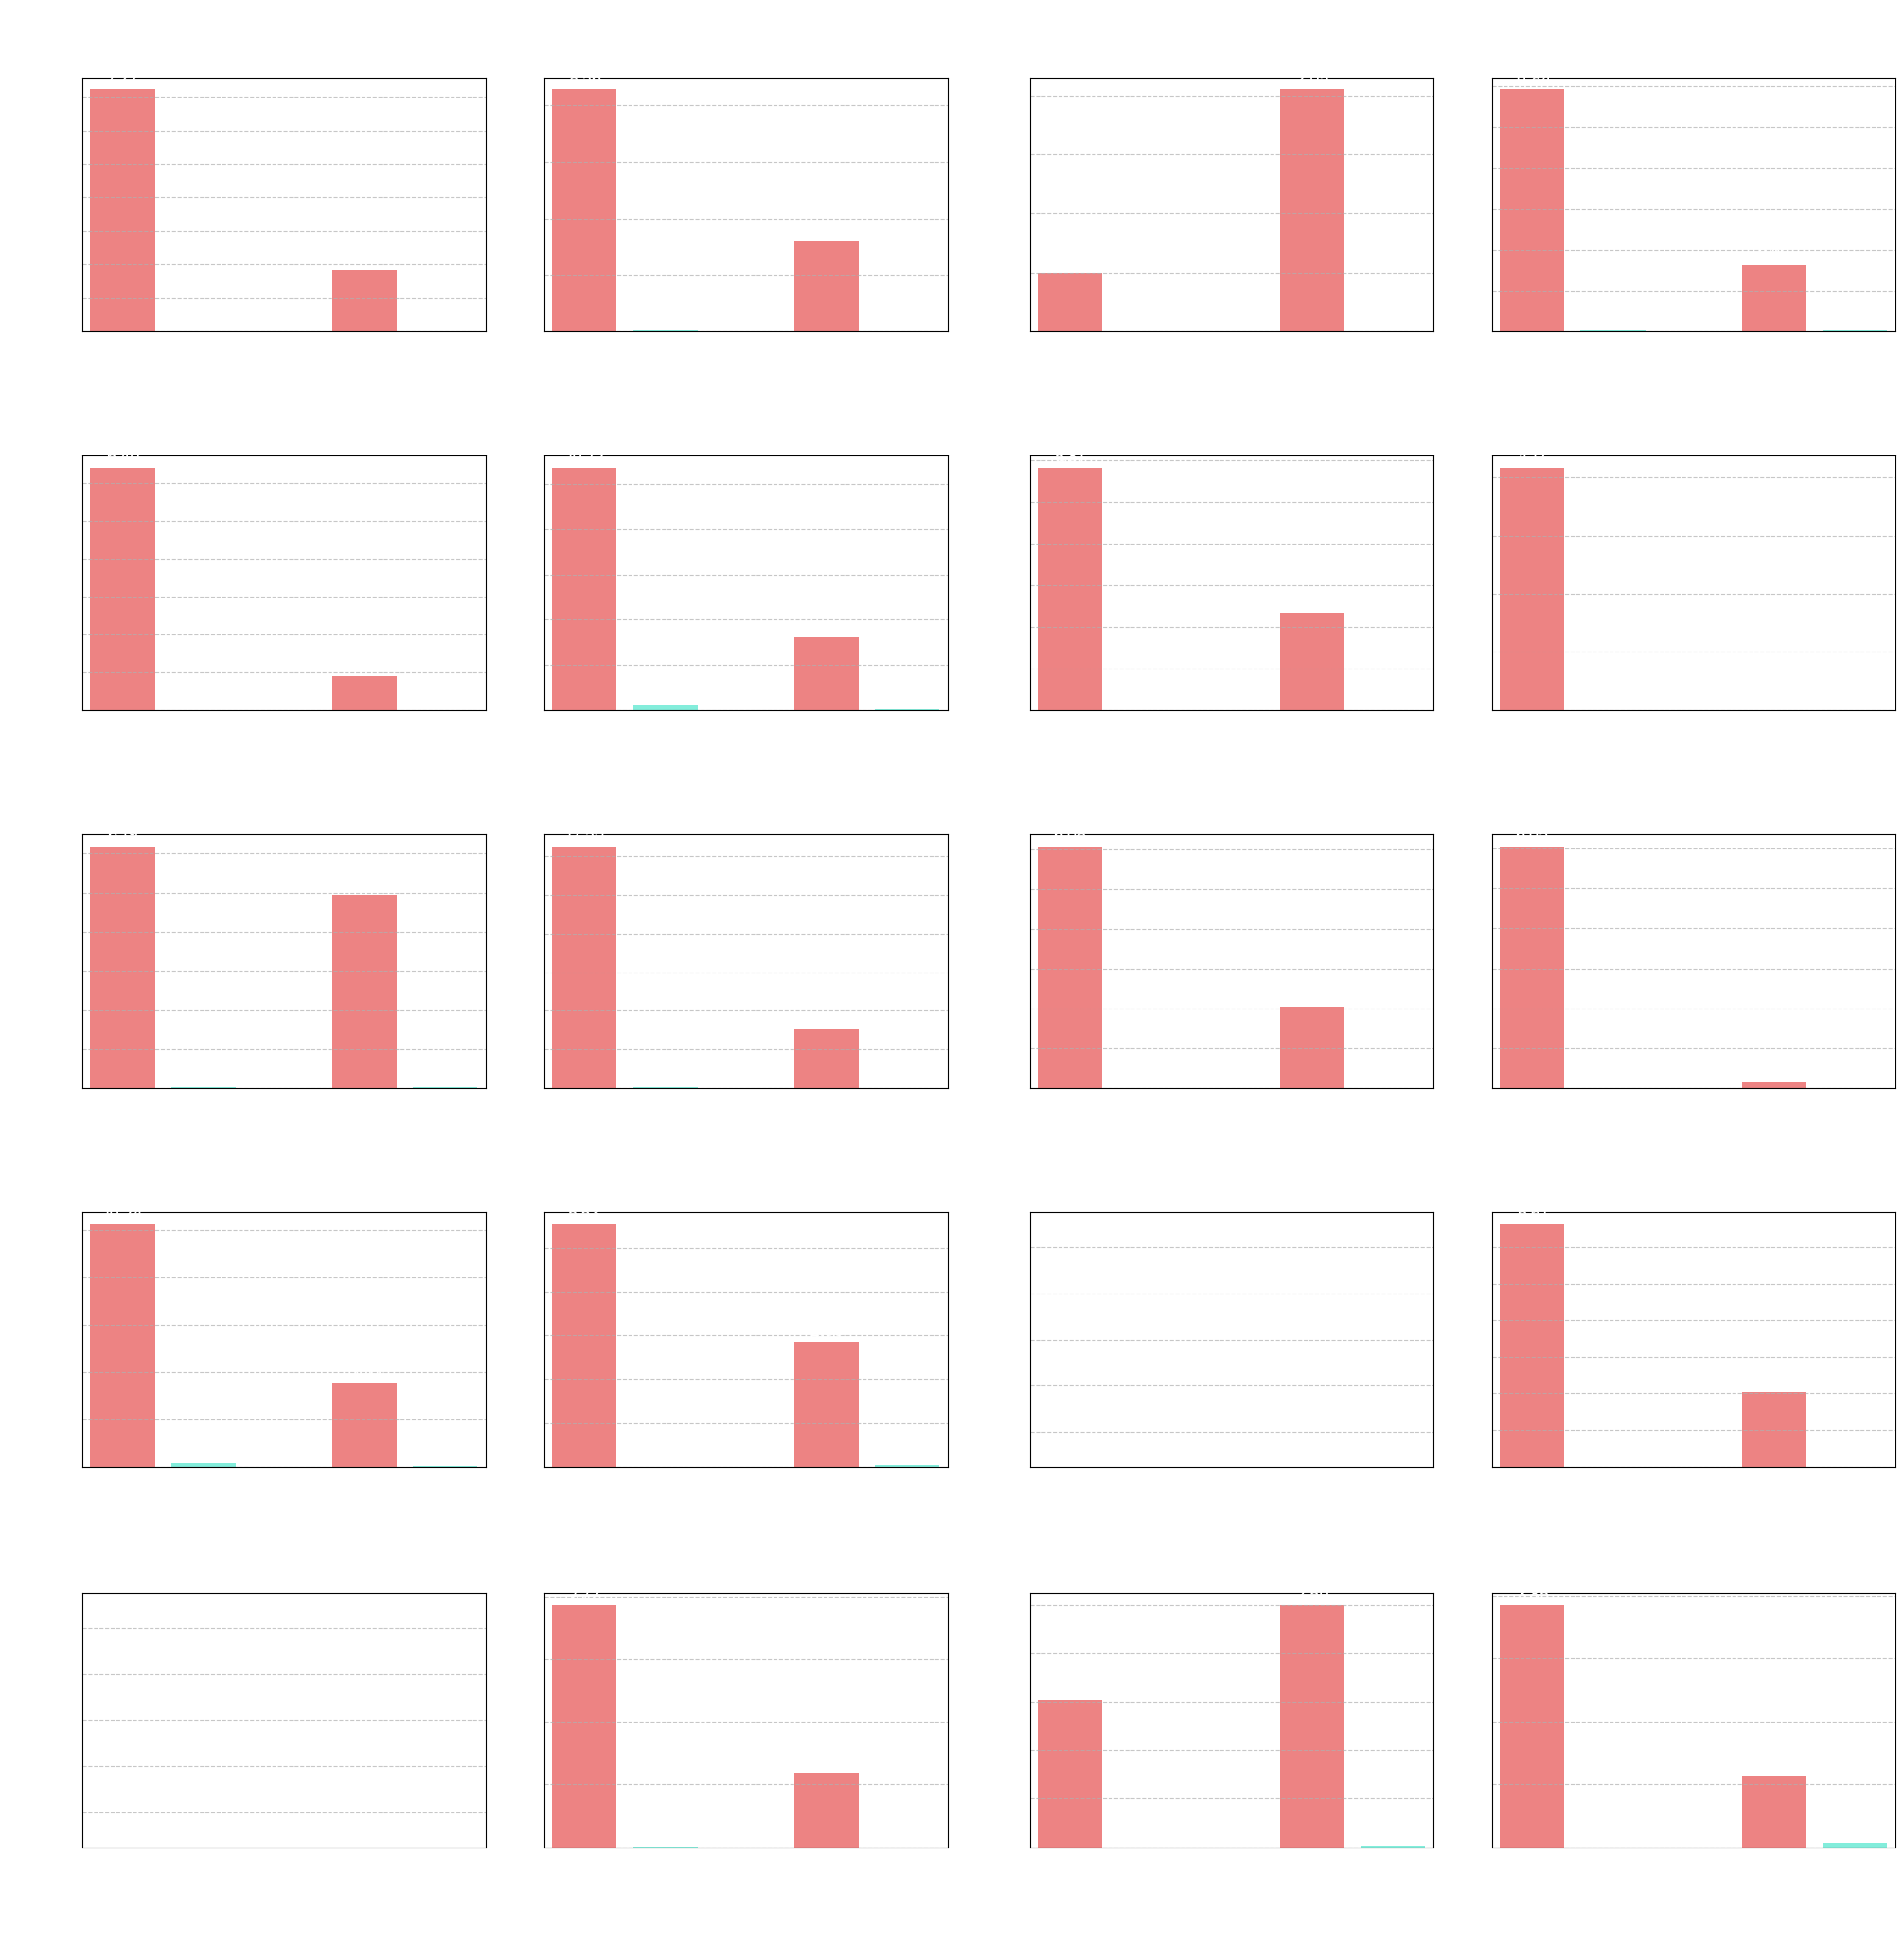

브랜드별 상품명 평균 품사 및 특수문자 개수 시각화 완료.


In [116]:
import matplotlib.pyplot as plt
import seaborn as sns
import math
import pandas as pd

# 각 브랜드별 평균 품사 및 특수문자 개수 계산
brand_avg_counts = []

for brand_name, brand_df in brand_dfs.items():
    if brand_df.empty:
        continue

    avg_noun = brand_df['product_name_okt_noun_count'].mean()
    avg_unicode_emoji = brand_df['product_name_unicode_emoji_count'].mean()
    avg_textual_emoji = brand_df['product_name_textual_emoji_count'].mean()
    avg_separator = brand_df['product_name_separator_count'].mean()
    avg_other_symbol = brand_df['product_name_other_symbol_count'].mean()

    brand_avg_counts.append({
        'Brand': brand_name,
        'Category': '명사',
        'Average_Count': avg_noun
    })
    brand_avg_counts.append({
        'Brand': brand_name,
        'Category': '유니코드 이모지',
        'Average_Count': avg_unicode_emoji
    })
    brand_avg_counts.append({
        'Brand': brand_name,
        'Category': '텍스트 이모지',
        'Average_Count': avg_textual_emoji
    })
    brand_avg_counts.append({
        'Brand': brand_name,
        'Category': '구분자',
        'Average_Count': avg_separator
    })
    brand_avg_counts.append({
        'Brand': brand_name,
        'Category': '기타 특수문자',
        'Average_Count': avg_other_symbol
    })

df_brand_avg_counts = pd.DataFrame(brand_avg_counts)

# 시각화를 위한 subplot 그리드 설정
num_brands = df_brand_avg_counts['Brand'].nunique()
n_cols = 4  # 한 줄에 4개의 차트
n_rows = math.ceil(num_brands / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), constrained_layout=True) # constrained_layout=True 로 타이틀 겹침 방지
axes = axes.flatten() # 1D 배열로 평탄화

# 각 브랜드별로 시각화
for i, brand_name in enumerate(df_brand_avg_counts['Brand'].unique()):
    ax = axes[i]
    brand_data = df_brand_avg_counts[df_brand_avg_counts['Brand'] == brand_name]
    bars = sns.barplot(x='Category', y='Average_Count', data=brand_data, palette=CUSTOM_PALETTE, ax=ax, hue='Category', legend=False)

    ax.set_title(f'{brand_name} 상품명 평균 개수', fontsize=20, color='white')
    ax.set_xlabel('', color='white') # x축 라벨 제거 (깔끔하게)
    ax.set_ylabel('평균 개수', fontsize=15, color='white')
    ax.tick_params(axis='x', rotation=45, labelsize=12, colors='white')
    ax.tick_params(axis='y', labelsize=12, colors='white')
    ax.grid(axis='y', linestyle='--', alpha=0.7)

    # 각 막대 위에 빈도수 값 표시
    for bar in bars.patches:
        ax.annotate(f'{bar.get_height():.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=12, color='white')

# 남은 빈 subplot이 있다면 비활성화
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('브랜드별 상품명 평균 품사 및 특수문자 개수 비교', fontsize=20, y=1.02, color='white') # 전체 제목
# plt.tight_layout() # constrained_layout 사용 시 필요 없음
plt.savefig('브랜드별_상품명_명사_특수문자_개수_비교.png', transparent=True)
plt.show()

print("브랜드별 상품명 평균 품사 및 특수문자 개수 시각화 완료.")


In [105]:
#이모지 목록
import emoji

all_extracted_unicode_emojis = set()

for brand_name, brand_df in brand_dfs.items():
    # 'product_name' 컬럼이 문자열이고 비어있지 않은 경우에만 처리
    for product_name in brand_df['product_name'].dropna().astype(str):
        # emoji.emoji_list는 이모지 객체 리스트를 반환합니다. 각 객체에서 'emoji' 키를 추출합니다.
        emojis_in_name = [emo['emoji'] for emo in emoji.emoji_list(product_name)]
        for emo in emojis_in_name:
            all_extracted_unicode_emojis.add(emo)

print(f"총 {len(all_extracted_unicode_emojis)}개의 고유 유니코드 이모지가 상품명에서 추출되었습니다.")
print("추출된 유니코드 이모지 목록:")
for emo in sorted(list(all_extracted_unicode_emojis)):
    print(f"- {emo}")

if not all_extracted_unicode_emojis:
    print("상품명에서 유니코드 이모지가 발견되지 않았습니다.")

총 22개의 고유 유니코드 이모지가 상품명에서 추출되었습니다.
추출된 유니코드 이모지 목록:
- ®
- ™
- ☀️
- ☁
- ☁️
- ☂️
- ☃
- ☃️
- ☘
- ♂️
- ♥
- ♨️
- ⛄
- ✂️
- ✨
- ❄
- ❄️
- ❣
- ❣️
- ❤
- ❤️
- ⭐


In [106]:
# 1. 개수 카운팅 함수 정의
def analyze_product_name_counts(text):
    if not isinstance(text, str) or not text.strip():
        return {
            '명사': 0, '형용사': 0, '동사': 0, '수사': 0, '조사': 0, '어미': 0,
            '유니코드 이모지': 0, '텍스트 이모티콘': 0, '구분자': 0, '기타 특수문자': 0
        }
    # (1) 형태소 분석 (Okt 이용)
    pos_tags = okt.pos(text)
    noun_cnt = sum(1 for _, tag in pos_tags if tag == 'Noun')
    adj_cnt = sum(1 for _, tag in pos_tags if tag == 'Adjective')
    verb_cnt = sum(1 for _, tag in pos_tags if tag == 'Verb')
    num_cnt = sum(1 for _, tag in pos_tags if tag == 'Number')
    josa_cnt = sum(1 for _, tag in pos_tags if tag == 'Josa')
    eomi_cnt = sum(1 for _, tag in pos_tags if tag == 'Eomi')

    # (2) 이모지 및 특수문자 카운팅
    # 유니코드 이모지 (예: ✨, ❤️ 등)
    emoji_cnt = len([c for c in text if c in emoji.EMOJI_DATA])

    # 텍스트 이모티콘 (예: ^^, ㅠㅠ, :) 등)
    emoticon_pattern = r'(\^\^|::-?\(|::-?\)|ㅠㅠ|ㅜㅜ|;\s*;)'
    emoticon_cnt = len(re.findall(emoticon_pattern, text))

    # 구분자 (예: [, ], (, ), /, -, _, ~ 등)
    sep_pattern = r'[\[\]\(\)\/\\_\-~|,]'
    sep_cnt = len(re.findall(sep_pattern, text))

    # 기타 특수문자 (한글, 영문, 숫자, 공백, 위에서 센 특수문자 제외)
    # 일반적인 특수문자 전체 개수에서 구분자/이모티콘 차감
    all_spec_cnt = len(re.findall(r'[^\s\w가-힣]', text))
    etc_spec_cnt = max(0, all_spec_cnt - emoji_cnt - sep_cnt)

    return {
        '명사': noun_cnt,
        '형용사': adj_cnt,
        '동사': verb_cnt,
        '수사': num_cnt,
        '조사': josa_cnt,
        '어미': eomi_cnt,
        '유니코드 이모지': emoji_cnt,
        '텍스트 이모티콘': emoticon_cnt,
        '구분자': sep_cnt,
        '기타 특수문자': etc_spec_cnt
    }

In [107]:
# 2. DataFrame 전체 상품명에 카운팅 함수 적용
count_results = df['product_name'].apply(analyze_product_name_counts)
df_counts = pd.DataFrame(list(count_results))

# 원본 DataFrame과 결합
df_analyzed = pd.concat([df[['product_name', 'brand_name']], df_counts], axis=1)

print("=== 상품명별 카운팅 결과 예시 ===")
display(df_analyzed.head(10))

=== 상품명별 카운팅 결과 예시 ===


,product_name,brand_name,명사,형용사,동사,수사,조사,어미,유니코드 이모지,텍스트 이모티콘,구분자,기타 특수문자
0,남성 쿨 원턱 와이드 트레이닝팬츠 PHG2PT1759,CJ,6,0,0,2,0,0,0,0,0,0
1,트레이닝 반바지 249PT262,CJ,2,0,0,2,0,0,0,0,0,0
2,남성 여성 커플 냉장고바지 쿨팬츠 8부 9부 아이스바지,CJ,9,0,0,2,1,0,0,0,0,0
3,캘빈클라인 에센셜 셋업 3종 세트 남여공용,CJ,8,0,0,1,0,0,0,0,0,0
4,7부 바지 스판 밴딩 냉장고 쿨링 아이스 냉감 칠부 츄리닝 트레이닝 팬츠,CJ,12,0,0,1,0,0,0,0,0,0
5,[마르치오] 남성 냉감 라운지웨어 상하의 4종 세트,CJ,7,1,0,1,1,0,0,0,2,0
6,여름 냉감 바지 트레이닝 오버사이즈 남성용 일자 (50365982),CJ,9,0,0,1,0,0,0,0,2,0
7,[롯데백화점] (행사)](남여공용) 프레시벤트 폴튼 트레이닝 쇼츠 DXTB7A053,CJ,10,0,1,2,0,0,0,0,7,0
8,[하프클럽] 25SS 신상 쉴드테크 남녀공용 이지팬츠 3종(7부),CJ,10,0,0,3,0,0,0,0,4,0
9,"[정가 89,000] 남여공용 밴딩 경량 크링클 트레이닝 팬츠",CJ,8,0,1,1,0,0,0,0,3,0


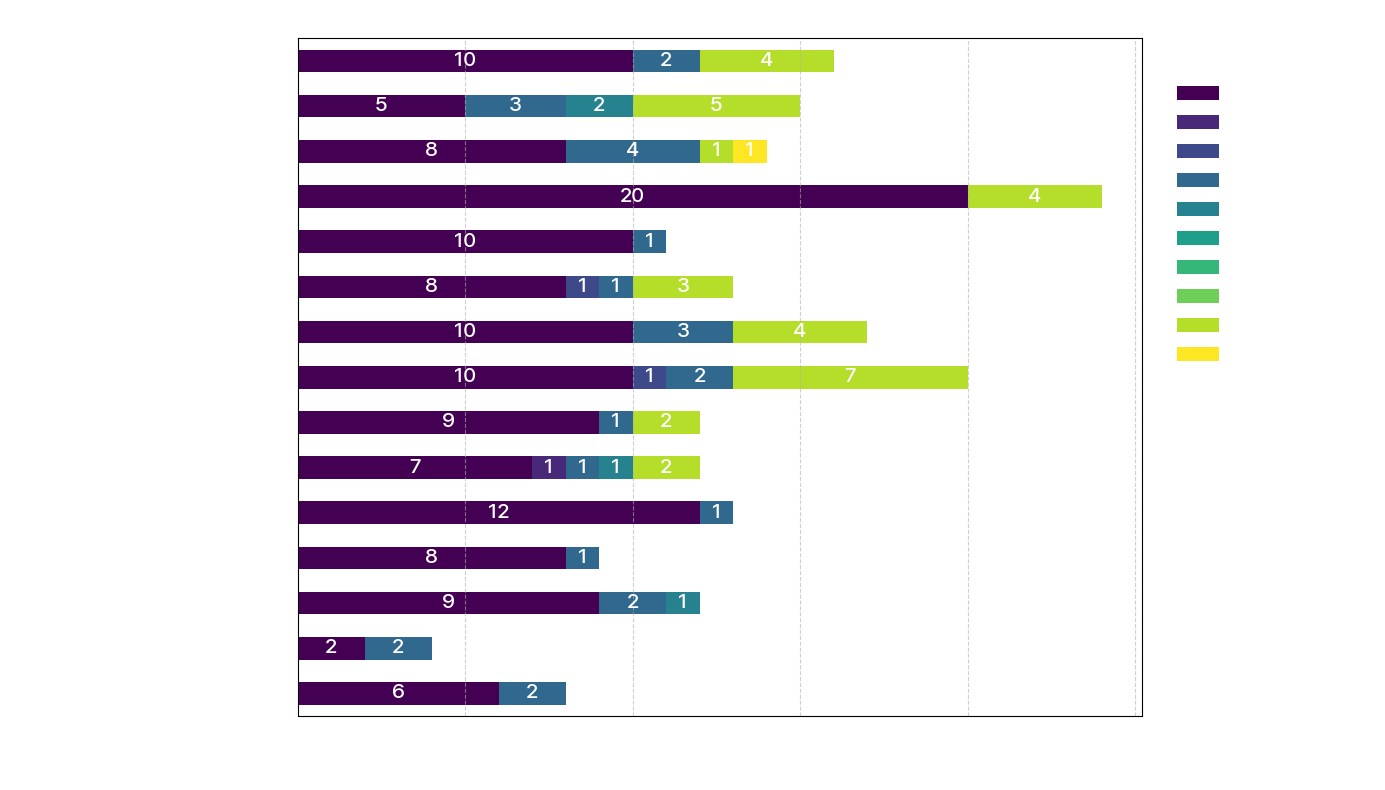

In [117]:
# 3. 시각화 (상위 N개 상품명 비교)
# 상품명이 너무 많으면 시각화가 빽빽해지므로 샘플 15개 추출 예시
sample_df = df_analyzed.head(15).copy()

# 시각화를 위한 상품명 길이 조절 (차트 라벨용)
sample_df['short_name'] = sample_df['product_name'].apply(lambda x: x[:15] + '...' if len(x) > 15 else x)

#상품명을 축약하지 않고 전체 이름 그대로 사용
sample_df['full_name'] = sample_df['product_name']

# (시각화 1) 누적 막대 그래프 (Stacked Bar Chart)
fig, ax = plt.subplots(figsize=(14,8))
categories = ['명사', '형용사', '동사', '수사', '조사', '어미', '유니코드 이모지', '텍스트 이모티콘', '구분자', '기타 특수문자']

sample_df.set_index('short_name')[categories].plot(
    kind='barh',
    stacked=True,
    ax=ax,
    colormap='viridis' # Use a colormap that works well with a dark background or define custom colors
)

plt.title('상품명 하나당 품사 및 특수문자 구성 개수 (상위 15개 샘플)', fontsize=20, fontweight='bold', color='white')
plt.xlabel('개수 카운트', fontsize=15, color='white')
plt.ylabel('상품명', fontsize=15, color='white')
plt.tick_params(axis='x', rotation=45, labelsize=15, colors='white')
plt.tick_params(axis='y', labelsize=15, colors='white')
plt.legend(title='구성 요소', bbox_to_anchor=(1.02, 1), loc='upper left', title_fontsize=15,fontsize=15, labelcolor='white', facecolor='none', edgecolor='white')
plt.grid(axis='x', linestyle='--', alpha=0.6)

#각 누적 막대 조각 내부에 수치(0보다 큰 값만) 표시
for container in ax.containers:
    # 각 수평 막대의 너비(width)가 0보다 큰 경우에만 해당 정수값을 표시
    labels = [f'{int(v.get_width())}' if v.get_width() > 0 else '' for v in container]
    ax.bar_label(
        container,
        labels=labels,
        label_type='center',  # 막대 조각 '중앙'에 위치
        fontsize=15,
        color='white',        # 가독성을 위해 흰색 글자 적용
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig('상품명별 품사&특수분자 구성(상위 15개).png', transparent=True)
plt.show()


In [109]:
# 1. 이모지 또는 이모티콘이 1개 이상 존재하는 상품명 데이터만 필터링
df_emoji_exist = df_analyzed[
    (df_analyzed['유니코드 이모지'] > 0) | (df_analyzed['텍스트 이모티콘'] > 0)
].copy()

print(f"이모지/이모티콘이 포함된 총 상품 수: {len(df_emoji_exist)}개")

이모지/이모티콘이 포함된 총 상품 수: 196개


/tmp/ipykernel_5777/1578335214.py:41: UserWarning: Glyph 9731 (\N{SNOWMAN}) missing from font(s) Pretendard.
  plt.tight_layout()
/tmp/ipykernel_5777/1578335214.py:41: UserWarning: Glyph 9729 (\N{CLOUD}) missing from font(s) Pretendard.
  plt.tight_layout()
/tmp/ipykernel_5777/1578335214.py:41: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Pretendard.
  plt.tight_layout()
/tmp/ipykernel_5777/1578335214.py:42: UserWarning: Glyph 9731 (\N{SNOWMAN}) missing from font(s) Pretendard.
  plt.savefig('상품명별 품사&특수분자 구성(이모지 포함).png', transparent=True)
/tmp/ipykernel_5777/1578335214.py:42: UserWarning: Glyph 9729 (\N{CLOUD}) missing from font(s) Pretendard.
  plt.savefig('상품명별 품사&특수분자 구성(이모지 포함).png', transparent=True)
/tmp/ipykernel_5777/1578335214.py:42: UserWarning: Glyph 65039 (\N{VARIATION SELECTOR-16}) missing from font(s) Pretendard.
  plt.savefig('상품명별 품사&특수분자 구성(이모지 포함).png', transparent=True)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:1

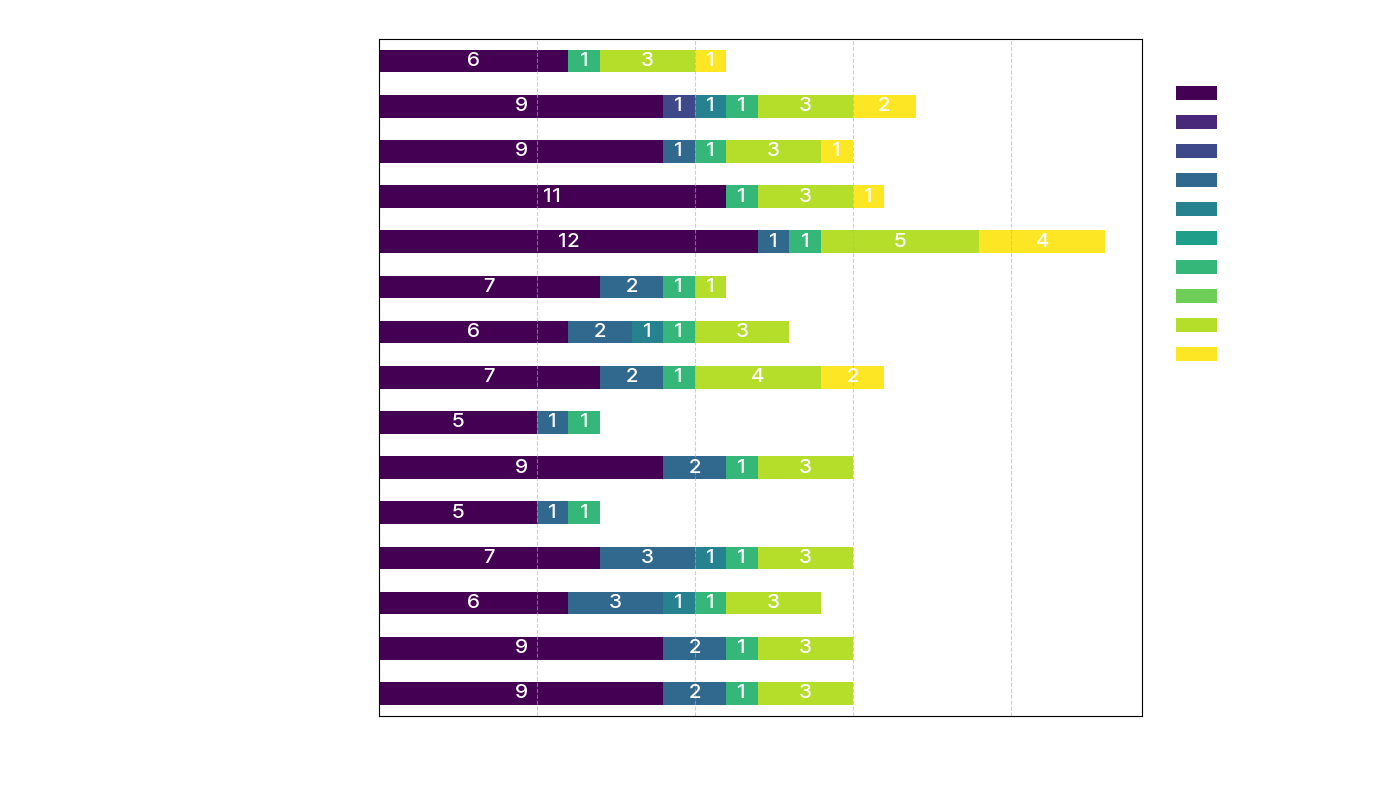

In [118]:
# 데이터가 존재할 경우 시각화 진행
if not df_emoji_exist.empty:
    # 상위 15개 샘플 추출 (데이터가 15개 미만이면 전체 사용)
    sample_emoji_df = df_emoji_exist.head(15).copy()

    # y축 라벨용 상품명 길이 정리
    sample_emoji_df['short_name'] = sample_emoji_df['product_name'].apply(
        lambda x: x[:18] + '...' if len(x) > 18 else x
    )

    categories = ['명사', '형용사', '동사', '수사', '조사', '어미', '유니코드 이모지', '텍스트 이모티콘', '구분자', '기타 특수문자']

    # (시각화 1) 누적 막대 그래프 (Stacked Bar Chart)
    fig, ax = plt.subplots(figsize=(14, 8))
    sample_emoji_df.set_index('short_name')[categories].plot(
        kind='barh',
        stacked=True,
        ax=ax,
        colormap='viridis'
    )
    plt.title('이모지/이모티콘 포함 상품명의 구성 개수 분석 (상위 샘플)', fontsize=20, fontweight='bold', color='white')
    plt.xlabel('개수 카운트', fontsize=15, color='white')
    plt.ylabel('상품명', fontsize=15, color='white')
    plt.tick_params(axis='x', rotation=45, labelsize=15, colors='white')
    plt.tick_params(axis='y', labelsize=15, colors='white')
    plt.legend(title='구성 요소', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=15, title_fontsize=15, labelcolor='white', facecolor='none', edgecolor='white')
    plt.grid(axis='x', linestyle='--', alpha=0.6)
    #각 누적 막대 조각 내부에 수치(0보다 큰 값만) 표시
    for container in ax.containers:
        # 각 수평 막대의 너비(width)가 0보다 큰 경우에만 해당 정수값을 표시
        labels = [f'{int(v.get_width())}' if v.get_width() > 0 else '' for v in container]
        ax.bar_label(
            container,
            labels=labels,
            label_type='center',  # 막대 조각 '중앙'에 위치
            fontsize=15,
            color='white',        # 가독성을 위해 흰색 글자 적용
            fontweight='bold'
        )

    plt.tight_layout()
    plt.savefig('상품명별 품사&특수분자 구성(이모지 포함).png', transparent=True)

    plt.show()
